# COMET trajectory diagnostics — five experiments

Read-only diagnostics on the hematopoiesis (Velten) dataset. Nothing here changes the model;
every cell produces a number and a plot. Run top to bottom.

**What each experiment decides**

| # | Question | Decision it makes |
|---|---|---|
| 1 | Are FPS archetypes the right ones? | keep FPS vs switch to PCHA + intrinsic dimension |
| 2 | Do our gene-space displacements mean anything? | is the flow real or a radial artifact |
| 3 | Is `project_to_2d` faithful? | trust / retune / replace the projection |
| 4 | What observable marks the origin? | which scalar becomes the root detector |
| 5 | Is the ATAC↔RNA pseudo-pairing real? | keep current matcher vs switch |

---

## Section 0 — Config, load, ground truth

In [1]:
import os, json, warnings, itertools
import numpy as np, pandas as pd, scipy.io
import anndata as ad, scanpy as sc
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.sparse import lil_matrix, issparse
from scipy.stats import spearmanr, pearsonr, rankdata
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import roc_auc_score
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore")
mpl.rcParams.update({"figure.dpi": 130, "savefig.dpi": 150, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(0)

BASE    = "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline"
DIAG    = "diagnostics_out"; os.makedirs(DIAG, exist_ok=True)

RNA_H5AD      = f"{BASE}/velten_rna.h5ad"
PEAK_TF_MTX   = f"{BASE}/peak_tf.mtx"
TF_NAMES_TXT  = f"{BASE}/tf_names.txt"
PEAK_GENE_CSV = f"{BASE}/peak_gene.csv"
PEAKS_TXT     = f"{BASE}/peaks.txt"
ATAC_MTX      = f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.mtx.gz"
ATAC_PEAKS    = f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.peaks.txt.gz"
DECIPHER_NPZ  = f"{BASE}/models/decipher_outputs2/decipher_embeddings.npz"

N_TOP_HVG, D_ATOMS, K_MOMENT, N_MATCH_PCS = 3000, 4, 5, 20
PSEUDOTIME_KEY = "facs_pseudotime"

def as_dense(x): return x.toarray() if issparse(x) else np.asarray(x)
def zscore_cols(A, eps=1e-8):
    A = np.asarray(A, dtype=np.float32)
    return (A - A.mean(0, keepdims=True)) / (A.std(0, keepdims=True) + eps)
def unit(v, axis=-1, eps=1e-12):
    return v / (np.linalg.norm(v, axis=axis, keepdims=True) + eps)
def cos_rows(A, B): return (unit(A, 1) * unit(B, 1)).sum(1)

### 0.1 Load (identical to `reworked.md` Steps 1–5)

In [2]:
rna_adata = ad.read_h5ad(RNA_H5AD)
sc.pp.normalize_total(rna_adata, target_sum=1e4); sc.pp.log1p(rna_adata)
sc.pp.highly_variable_genes(rna_adata, n_top_genes=N_TOP_HVG, subset=False)
hvg_genes = set(rna_adata.var_names[rna_adata.var['highly_variable']])

gene_names_all   = np.array(rna_adata.var_names.astype(str))
gene_to_idx_full = {g: i for i, g in enumerate(gene_names_all)}
X_full = as_dense(rna_adata.X).astype(np.float32)

peak_tf = scipy.io.mmread(PEAK_TF_MTX).tocsr()
motif_tf_names  = open(TF_NAMES_TXT).read().strip().split()
motif_tf_to_idx = {t: i for i, t in enumerate(motif_tf_names)}
peak_gene   = pd.read_csv(PEAK_GENE_CSV, sep="\t")
peaks       = pd.read_csv(PEAKS_TXT, header=None)[0].astype(str).tolist()
peak_to_idx = {p: i for i, p in enumerate(peaks)}

genes_in_peaks = set(peak_gene["gene"].astype(str).unique())
A_tfs   = np.array([t for t in motif_tf_names if t in gene_to_idx_full], dtype=str)
A_genes = np.array([g for g in gene_names_all
                    if (g in genes_in_peaks and g in hvg_genes) or g in A_tfs], dtype=str)
gene_idx = np.array([gene_to_idx_full[g] for g in A_genes], dtype=int)
X        = X_full[:, gene_idx]
sub_g2i  = {g: i for i, g in enumerate(A_genes)}

P, G = len(peaks), len(A_genes)
pgm = lil_matrix((P, G), dtype=np.float32)
for _, r in peak_gene.iterrows():
    p, g = str(r["peak"]), str(r["gene"])
    if p in peak_to_idx and g in sub_g2i: pgm[peak_to_idx[p], sub_g2i[g]] = 1.0
M_full = ((pgm.tocsr().T @ peak_tf) > 0).astype(np.float32)

A_tfs  = np.array([t for t in A_tfs if t in motif_tf_to_idx], dtype=str)
tf_idx = np.array([gene_to_idx_full[t] for t in A_tfs], dtype=int)
tf_col = np.array([motif_tf_to_idx[t] for t in A_tfs], dtype=int)
X_TF   = X_full[:, tf_idx]
M      = M_full[:, tf_col].toarray().astype(np.float32)
tf_indices_in_G = np.array([sub_g2i[t] for t in A_tfs], dtype=int)

atac_raw = scipy.io.mmread(ATAC_MTX).tocsr()
atac_X   = atac_raw.T.astype(np.float32)
peaks_atac = pd.read_csv(ATAC_PEAKS, sep="\t")
peak_names = peaks_atac["Feature"].str.replace("_", ":", n=1).str.replace("_", "-", n=1).tolist()
peak_to_idx_atac = {p: i for i, p in enumerate(peak_names)}
pgm2 = lil_matrix((len(peak_names), G), dtype=np.float32)
for _, r in peak_gene.iterrows():
    p, g = str(r["peak"]).replace("-", ":", 1), str(r["gene"])
    if p in peak_to_idx_atac and g in sub_g2i: pgm2[peak_to_idx_atac[p], sub_g2i[g]] = 1.0
gene_activity = np.log1p(as_dense(
    normalize(atac_X @ pgm2.tocsr(), norm="l1", axis=1))).astype(np.float32)
atac_depth = np.asarray(atac_X.sum(1)).ravel()          # per-ATAC-cell total signal
atac_nfrag = np.asarray((atac_X > 0).sum(1)).ravel()    # per-ATAC-cell peaks open

dec    = np.load(DECIPHER_NPZ)
Z_dec  = dec["z"].astype(np.float32)
V_dec2 = dec["v"].astype(np.float32)
pt_raw = rna_adata.obs[PSEUDOTIME_KEY].astype(np.float32).values
pt_raw = (pt_raw - np.nanmin(pt_raw)) / (np.ptp(pt_raw) + 1e-8)
N = X.shape[0]
print(f"N={N}  G={G}  T={len(A_tfs)}  ATAC cells={gene_activity.shape[0]}")

N=1035  G=3016  T=277  ATAC cells=18489


### 0.2 Cell types, smoothed pseudotime, neighbor graph

FACS pseudotime is scattered, so we kNN-smooth it once and use the smoothed version as the
reference ordering everywhere below. Smoothing is monotone-preserving and reduces label
noise; we report how much it changes the ordering.

CLOUD    246
MEP      213
GMP      198
MPP      139
HSC      127
MLP       75
CMP       37
smoothed vs raw pseudotime Spearman = +0.786


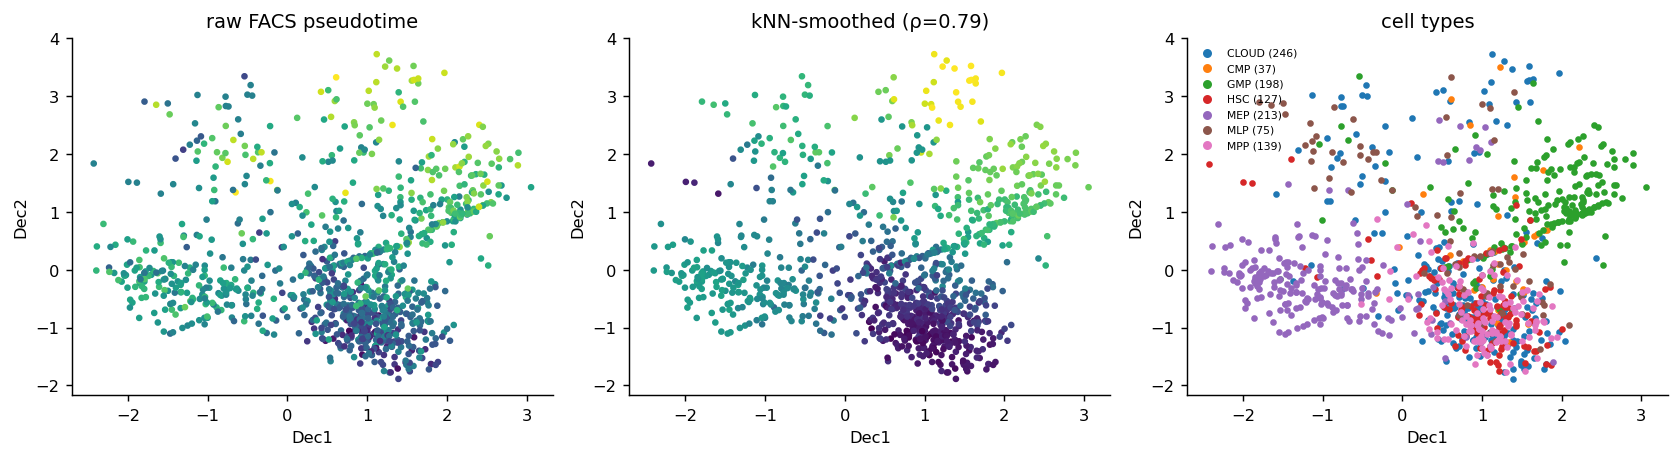

In [3]:
def assign_velten_celltypes(obs, X_full, g2i):
    n = len(obs)
    MARK = {'HSC':['CD34','THY1','PROM1','ITGA6'], 'MPP':['CD34','FLT3','GATA2'],
            'MLP':['CD34','IL7R','FLT3','DNTT'],   'CMP':['CD34','FLT3','CSF1R','CEBPA'],
            'MEP':['GATA1','GATA2','KLF1','EPOR','GYPA'],
            'GMP':['MPO','ELANE','SPI1','LYZ','CEBPA']}
    sc_ = {}
    for ct, ms in MARK.items():
        s, k = np.zeros(n, np.float32), 0
        for g in ms:
            if g in g2i:
                e = np.log1p(X_full[:, g2i[g]].astype(np.float32))
                s += (e - e.mean()) / (e.std() + 1e-8); k += 1
        sc_[ct] = s / max(k, 1)
    sdf = pd.DataFrame(sc_)
    def q(col, pct, above=True):
        if col not in obs.columns: return np.zeros(n, bool)
        t = obs[col].quantile(pct/100)
        return (obs[col] > t) if above else (obs[col] <= t)
    base = q('facs_lin',30,False) & q('facs_cd34',40,True)
    d_lo, d_hi = q('facs_cd38',33,False), q('facs_cd38',50,True)
    ct = np.full(n, 'CLOUD', dtype=object)
    ct[base & d_hi &  q('facs_cd45ra',50,True)]                                = 'GMP'
    ct[base & d_hi &  q('facs_cd135',40,False) & q('facs_cd45ra',50,False)]    = 'MEP'
    ct[base & d_hi &  q('facs_cd135',40,True)  & q('facs_cd45ra',50,False)]    = 'CMP'
    ct[base & d_lo &  q('facs_cd45ra',50,True)]                                = 'MLP'
    ct[base & d_lo & ~q('facs_cd90',50,True)   & q('facs_cd45ra',50,False)]    = 'MPP'
    ct[base & d_lo &  q('facs_cd90',50,True)   & q('facs_cd45ra',50,False)]    = 'HSC'
    ci = np.where(ct == 'CLOUD')[0]
    b, bs, names = sdf.values[ci].argmax(1), sdf.values[ci].max(1), list(sdf.columns)
    for i, bb, ss in zip(ci, b, bs):
        if ss > 0.5: ct[i] = names[bb]
    return ct

cell_types = assign_velten_celltypes(rna_adata.obs, X_full, gene_to_idx_full)
print(pd.Series(cell_types).value_counts().to_string())

K_GRAPH = 30
nn_graph = NearestNeighbors(n_neighbors=K_GRAPH).fit(Z_dec)
_, NB = nn_graph.kneighbors(Z_dec)                       # (N, K_GRAPH)

def knn_smooth(sig, nb=NB, k=15, rounds=1):
    out = np.asarray(sig, np.float32).copy()
    for _ in range(rounds): out = out[nb[:, :k]].mean(1)
    return out

pt = knn_smooth(pt_raw, k=15, rounds=2)
pt = (pt - pt.min()) / (np.ptp(pt) + 1e-8)
rho_sm = spearmanr(pt_raw, pt).correlation
print(f"smoothed vs raw pseudotime Spearman = {rho_sm:+.3f}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].scatter(*V_dec2.T, c=pt_raw, cmap='viridis', s=7); ax[0].set_title('raw FACS pseudotime')
ax[1].scatter(*V_dec2.T, c=pt,     cmap='viridis', s=7); ax[1].set_title(f'kNN-smoothed (ρ={rho_sm:.2f})')
for t in np.unique(cell_types):
    m = cell_types == t
    ax[2].scatter(V_dec2[m,0], V_dec2[m,1], s=7, label=f"{t} ({m.sum()})")
ax[2].legend(fontsize=6, markerscale=1.5, frameon=False); ax[2].set_title('cell types')
for a in ax: a.set_xlabel('Dec1'); a.set_ylabel('Dec2')
plt.tight_layout(); plt.savefig(f"{DIAG}/00_overview.png", bbox_inches='tight'); plt.show()

### 0.3 Ground-truth regions

In [4]:
TRUE_ORIGIN = np.isin(cell_types, ['HSC', 'MPP']) & (pt < np.quantile(pt, 0.35))
cen = V_dec2.mean(0)
d_cen = np.linalg.norm(V_dec2 - cen, axis=1)
CENTER = d_cen < np.quantile(d_cen, 0.15)            # the "hub" that keeps winning
EARLY  = pt < np.quantile(pt, 0.20)
LATE   = pt > np.quantile(pt, 0.80)
print(f"TRUE_ORIGIN n={TRUE_ORIGIN.sum()} | CENTER n={CENTER.sum()} | overlap={np.sum(TRUE_ORIGIN&CENTER)}")
print(f"origin centroid  = {V_dec2[TRUE_ORIGIN].mean(0).round(2)}")
print(f"center centroid  = {V_dec2[CENTER].mean(0).round(2)}")

TRUE_ORIGIN n=192 | CENTER n=156 | overlap=32
origin centroid  = [ 0.95 -0.87]
center centroid  = [ 0.74 -0.03]


---

## Experiment 1 — Archetypes: FPS vs PCHA + intrinsic dimension

Current selection is furthest-point sampling on `Z_dec`, which by construction lands on the
*most extreme cells* — i.e. maximally on outliers — and takes `D=4` as a fixed input.
Starfysh's recipe replaces both: **PCHA** fits a convex polytope (archetypes are convex
combinations of cells, so they are robust to single outliers), and the number of archetypes
is chosen from the **intrinsic dimension** plus an explained-variance convergence check.

### 1.1 Intrinsic dimension (Fisher separability)

In [5]:
def fisher_separability_id(Xp, alpha=0.8, n_sample=2000, seed=0):
    """Albergante/Gorban Fisher-separability ID. Returns (id_estimate, p_alpha)."""
    r = np.random.default_rng(seed)
    Y = Xp[r.choice(len(Xp), min(n_sample, len(Xp)), replace=False)]
    Y = Y - Y.mean(0)
    C = np.cov(Y, rowvar=False)
    w, V = np.linalg.eigh(C); w = np.clip(w, 1e-10, None)
    Yw = (Y @ V) / np.sqrt(w)                       # whiten
    Yw = unit(Yw, 1)                                # project to sphere
    Gm = Yw @ Yw.T; np.fill_diagonal(Gm, -np.inf)
    p = float((Gm > alpha).sum() / (len(Yw) * (len(Yw) - 1)))
    p = max(p, 1e-12)
    # invert p_alpha(n) = (1-alpha^2)^((n-1)/2) / (alpha*sqrt(2*pi*n)) approximately
    ns = np.arange(1, 201, dtype=float)
    pred = (1 - alpha**2)**((ns - 1)/2) / (alpha * np.sqrt(2*np.pi*ns))
    return float(ns[np.argmin(np.abs(np.log(pred) - np.log(p)))]), p

X_pca30 = PCA(n_components=30, random_state=0).fit_transform(X)
for a in [0.7, 0.8, 0.9]:
    idv, pa = fisher_separability_id(X_pca30, alpha=a)
    print(f"alpha={a}: intrinsic dim ≈ {idv:.0f}   (p_alpha={pa:.2e})")
id_est, _ = fisher_separability_id(X_pca30, alpha=0.8)
K_SUGGEST = int(id_est) + 1        # a d-simplex has d+1 vertices
print(f"\n→ suggested #archetypes from ID = {K_SUGGEST}   (current D_ATOMS = {D_ATOMS})")

alpha=0.7: intrinsic dim ≈ 14   (p_alpha=2.17e-03)
alpha=0.8: intrinsic dim ≈ 12   (p_alpha=5.16e-04)
alpha=0.9: intrinsic dim ≈ 11   (p_alpha=2.80e-05)

→ suggested #archetypes from ID = 13   (current D_ATOMS = 4)


### 1.2 PCHA

K= 2  explained variance = 0.1681
K= 3  explained variance = 0.2998
K= 4  explained variance = 0.3686
K= 5  explained variance = 0.3986
K= 6  explained variance = 0.4142
K= 7  explained variance = 0.4120
K= 8  explained variance = 0.4236
K= 9  explained variance = 0.4355
K=10  explained variance = 0.4372

→ EV converges (ΔEV<0.01) at K = 7
→ K_USE = 7


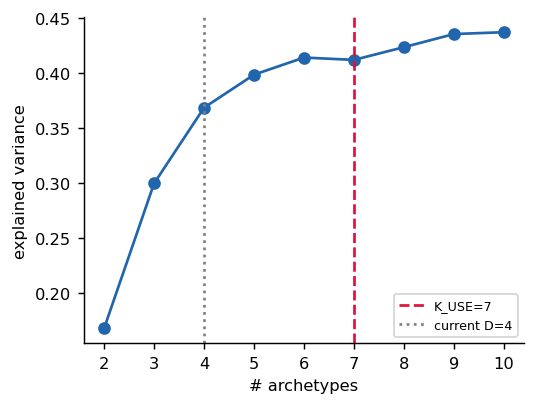

In [8]:
import numpy as np

def pcha(Xp, K, delta=0.0, n_iter=200, tol=1e-6, seed=0):
    """Stabilized Principal Convex Hull Analysis (Morup & Hansen)."""
    r = np.random.default_rng(seed)
    n, p = Xp.shape
    
    # 1. Initialize B (one-hot) and W (uniform)
    B = np.zeros((K, n))
    B[np.arange(K), r.choice(n, K, replace=False)] = 1.0
    W = np.full((n, K), 1.0 / K)
    
    # Precalculate Gram matrix and total variance around mean
    Xp_centered = Xp - Xp.mean(axis=0)
    sst = float((Xp_centered ** 2).sum())
    XtX = Xp @ Xp.T
    
    prev_sse = np.inf
    
    for it in range(n_iter):
        Arch = B @ Xp
        AtA = Arch @ Arch.T
        XA = Xp @ Arch.T
        
        # --- Update W (Cell -> Archetype weights) ---
        # Lipschitz constant for W update
        L_W = np.linalg.norm(AtA, 2) + 1e-6
        for _ in range(10):
            gW = W @ AtA - XA
            W = W - gW / L_W
            W = np.clip(W, 0, None)
            W /= (W.sum(axis=1, keepdims=True) + 1e-12)
            
        # --- Update B (Archetype -> Cell weights) ---
        WtW = W.T @ W
        # Lipschitz constant for B update
        L_B = np.linalg.norm(WtW, 2) * np.linalg.norm(XtX, 2) + 1e-6
        for _ in range(10):
            gB = WtW @ B @ XtX - W.T @ XtX
            B = B - gB / L_B
            B = np.clip(B, 0, None)
            B /= (B.sum(axis=1, keepdims=True) + 1e-12)
            
        # Calculate reconstruction error (SSE) centered
        Rec = W @ (B @ Xp)
        sse = float(((Xp - Rec) ** 2).sum())
        
        if abs(prev_sse - sse) / (sse + 1e-12) < tol:
            break
        prev_sse = sse
        
    # Proper Explained Variance relative to centered SST
    ev = 1.0 - (sse / sst)
    return B @ Xp, W, B, ev

ks = list(range(2, 11)); evs = []
for k in ks:
    _, _, _, ev = pcha(X_pca30, k, seed=0); evs.append(ev)
    print(f"K={k:2d}  explained variance = {ev:.4f}")
d_ev = np.diff(evs)
K_EV = ks[int(np.argmax(d_ev < 0.01)) + 1] if np.any(d_ev < 0.01) else ks[-1]
print(f"\n→ EV converges (ΔEV<0.01) at K = {K_EV}")
K_USE = int(np.clip(min(K_SUGGEST, K_EV), 3, 8))
print(f"→ K_USE = {K_USE}")

plt.figure(figsize=(4.2, 3.2))
plt.plot(ks, evs, 'o-', color='#2166ac')
plt.axvline(K_USE, ls='--', c='crimson', label=f'K_USE={K_USE}')
plt.axvline(D_ATOMS, ls=':', c='gray', label=f'current D={D_ATOMS}')
plt.xlabel('# archetypes'); plt.ylabel('explained variance'); plt.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{DIAG}/01_pcha_ev.png", bbox_inches='tight'); plt.show()

### 1.3 Hierarchical shrinkage + archetypal communities

In [9]:
def merge_close(Arch, r_frac=0.15, ref=None):
    ref = Arch if ref is None else ref
    scale = np.linalg.norm(ref - ref.mean(0), axis=1).mean()
    keep = [0]
    for i in range(1, len(Arch)):
        if min(np.linalg.norm(Arch[i] - Arch[j]) for j in keep) > r_frac * scale:
            keep.append(i)
    return np.array(keep)

Arch_p, W_pcha, B_pcha, ev = pcha(X_pca30, K_USE, seed=0)
keep = merge_close(Arch_p, 0.15, X_pca30)
Arch_p, W_pcha = Arch_p[keep], W_pcha[:, keep]
K_FINAL = len(keep)
print(f"after shrinkage: {K_FINAL} archetypes (EV={ev:.3f})")

# archetypal community = r nearest cells to each archetype (in PCA space)
R_COMM = 50
nn_p = NearestNeighbors(n_neighbors=R_COMM).fit(X_pca30)
_, comm_idx = nn_p.kneighbors(Arch_p)                    # (K_FINAL, R_COMM)
arch_idx_pcha = np.array([c[0] for c in comm_idx])       # nearest real cell (for plotting)

# --- current FPS method, for comparison ---
def fps_archetypes(Z, D, cell_types, k_neigh=50, purity_thresh=0.20, seed=0):
    c = Z.mean(0); first = int(np.argmax(((Z - c)**2).sum(1)))
    seeds = [first]; dmin = ((Z - Z[first])**2).sum(1)
    for _ in range(D - 1):
        nxt = int(np.argmax(dmin)); seeds.append(nxt)
        dmin = np.minimum(dmin, ((Z - Z[nxt])**2).sum(1))
    _, ind = NearestNeighbors(n_neighbors=k_neigh).fit(Z).kneighbors(Z[seeds])
    med = []
    for d in range(D):
        ni = ind[d]; lab = np.array(cell_types)[ni]
        vc = pd.Series(lab).value_counts(); maj, pur = vc.index[0], vc.iloc[0]/k_neigh
        core = ni[lab == maj] if pur >= purity_thresh else ni
        med.append(core[np.argmin(((Z[core] - Z[core].mean(0))**2).sum(1))])
    return np.array(med, int), ind

arch_idx_fps, comm_fps = fps_archetypes(Z_dec, D_ATOMS, cell_types)
print(f"FPS archetype cells : {arch_idx_fps.tolist()}")
print(f"PCHA archetype cells: {arch_idx_pcha.tolist()}")

after shrinkage: 7 archetypes (EV=0.412)
FPS archetype cells : [927, 29, 459, 677]
PCHA archetype cells: [981, 546, 180, 326, 328, 1033, 1032]


=== FPS Archetype Identities ===
FPS  #1 (Cell  927): GMP
FPS  #2 (Cell   29): MEP
FPS  #3 (Cell  459): MLP
FPS  #4 (Cell  677): GMP

=== PCHA Archetype Identities ===
PCHA #1 (Cell  981): GMP
PCHA #2 (Cell  546): GMP
PCHA #3 (Cell  180): HSC
PCHA #4 (Cell  326): MLP
PCHA #5 (Cell  328): MPP
PCHA #6 (Cell 1033): GMP
PCHA #7 (Cell 1032): MEP

→ Captures HSC Origin? FPS: False | PCHA: True


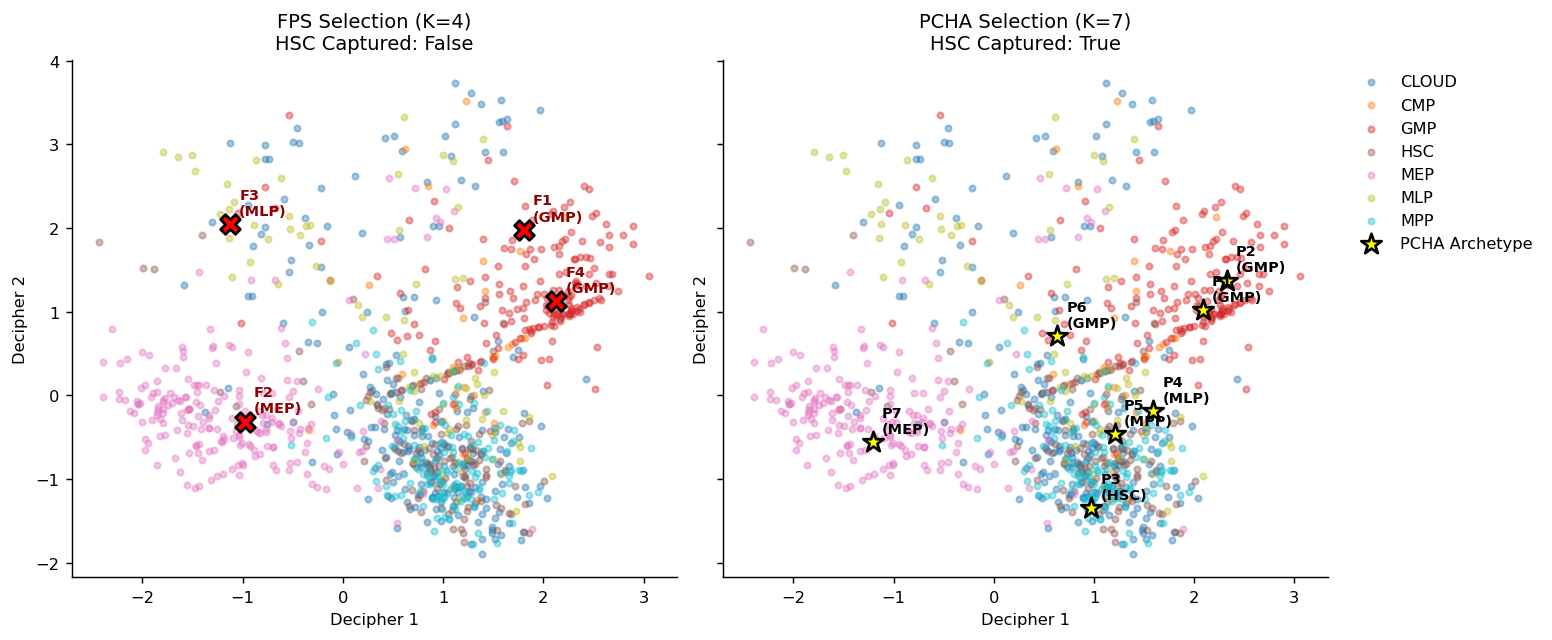

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Define archetype indices from your output
fps_indices = [927, 29, 459, 677]
pcha_indices = [981, 546, 180, 326, 328, 1033, 1032]

# --- 1. Print Cell Type Identifications for Each Archetype ---
print("=== FPS Archetype Identities ===")
for i, idx in enumerate(fps_indices):
    print(f"FPS  #{i+1} (Cell {idx:4d}): {cell_types[idx]}")

print("\n=== PCHA Archetype Identities ===")
for i, idx in enumerate(pcha_indices):
    print(f"PCHA #{i+1} (Cell {idx:4d}): {cell_types[idx]}")

# Check if HSC was captured
has_hsc_fps = any(cell_types[fps_indices] == 'HSC')
has_hsc_pcha = any(cell_types[pcha_indices] == 'HSC')
print(f"\n→ Captures HSC Origin? FPS: {has_hsc_fps} | PCHA: {has_hsc_pcha}")


# --- 2. Create Decipher Plot Overlaid with Archetypes ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

# Define clean color palette for cell types
unique_cts = np.unique(cell_types)
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_cts)))
ct_to_color = dict(zip(unique_cts, colors))

for ax in axes:
    # Plot background cell cloud colored by cell type
    for ct in unique_cts:
        mask = cell_types == ct
        ax.scatter(
            V_dec2[mask, 0], V_dec2[mask, 1],
            c=[ct_to_color[ct]], s=12, alpha=0.4, label=ct
        )
    ax.set_xlabel('Decipher 1')
    ax.set_ylabel('Decipher 2')

# Subplot 1: FPS Archetypes
axes[0].scatter(
    V_dec2[fps_indices, 0], V_dec2[fps_indices, 1],
    c='red', s=120, marker='X', edgecolors='black', linewidths=1.5,
    label='FPS Archetype', zorder=10
)
for i, idx in enumerate(fps_indices):
    axes[0].annotate(
        f'F{i+1}\n({cell_types[idx]})', 
        (V_dec2[idx, 0], V_dec2[idx, 1]),
        fontsize=8, fontweight='bold', color='darkred',
        xytext=(5, 5), textcoords='offset points', zorder=11
    )
axes[0].set_title(f'FPS Selection (K={len(fps_indices)})\nHSC Captured: {has_hsc_fps}')

# Subplot 2: PCHA Archetypes
axes[1].scatter(
    V_dec2[pcha_indices, 0], V_dec2[pcha_indices, 1],
    c='yellow', s=140, marker='*', edgecolors='black', linewidths=1.5,
    label='PCHA Archetype', zorder=10
)
for i, idx in enumerate(pcha_indices):
    axes[1].annotate(
        f'P{i+1}\n({cell_types[idx]})', 
        (V_dec2[idx, 0], V_dec2[idx, 1]),
        fontsize=8, fontweight='bold', color='black',
        xytext=(5, 5), textcoords='offset points', zorder=11
    )
axes[1].set_title(f'PCHA Selection (K={len(pcha_indices)})\nHSC Captured: {has_hsc_pcha}')

# Place legend cleanly outside or on top
axes[1].legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False, fontsize=9)

plt.tight_layout()
plt.savefig(f"{DIAG}/02_archetypes_in_decipher.png", bbox_inches='tight', dpi=300)
plt.show()

### 1.4 Head-to-head: purity, coverage, origin capture, stability

In [11]:
def community_stats(comm, name):
    rows = []
    for d, ni in enumerate(comm):
        lab = np.array(cell_types)[ni]
        vc = pd.Series(lab).value_counts()
        rows.append(dict(method=name, arch=d, majority=vc.index[0],
                         purity=vc.iloc[0]/len(ni),
                         mean_pt=pt[ni].mean(),
                         frac_origin=TRUE_ORIGIN[ni].mean()))
    return pd.DataFrame(rows)

stats = pd.concat([community_stats(comm_fps, 'FPS'), community_stats(comm_idx, 'PCHA')])
print(stats.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

def summary(comm, name):
    labs = [pd.Series(np.array(cell_types)[ni]).value_counts().index[0] for ni in comm]
    return dict(method=name,
                mean_purity=np.mean([pd.Series(np.array(cell_types)[ni]).value_counts().iloc[0]/len(ni) for ni in comm]),
                n_distinct_types=len(set(labs)),
                captures_origin=float(max(TRUE_ORIGIN[ni].mean() for ni in comm)),
                pt_spread=float(np.ptp([pt[ni].mean() for ni in comm])))
S = pd.DataFrame([summary(comm_fps,'FPS'), summary(comm_idx,'PCHA')])
print("\n", S.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

method  arch majority  purity  mean_pt  frac_origin
   FPS     0      GMP   0.400    0.876        0.000
   FPS     1      MEP   0.740    0.409        0.020
   FPS     2      MLP   0.580    0.558        0.000
   FPS     3      GMP   0.940    0.695        0.000
  PCHA     0      GMP   0.980    0.712        0.000
  PCHA     1      GMP   0.920    0.737        0.000
  PCHA     2    CLOUD   0.340    0.083        0.600
  PCHA     3      MLP   0.360    0.378        0.060
  PCHA     4    CLOUD   0.320    0.152        0.380
  PCHA     5      GMP   0.320    0.338        0.120
  PCHA     6      MEP   0.960    0.525        0.000

 method  mean_purity  n_distinct_types  captures_origin  pt_spread
   FPS        0.665                 3            0.020      0.467
  PCHA        0.600                 4            0.600      0.654


`captures_origin` is the number to watch: at least one archetype must sit in the HSC region,
otherwise the GRN atoms cannot represent the progenitor state at all.

bootstrap displacement (lower=better, units of data radius)
  FPS : 0.734 ± 0.269
  PCHA: 0.153 ± 0.033


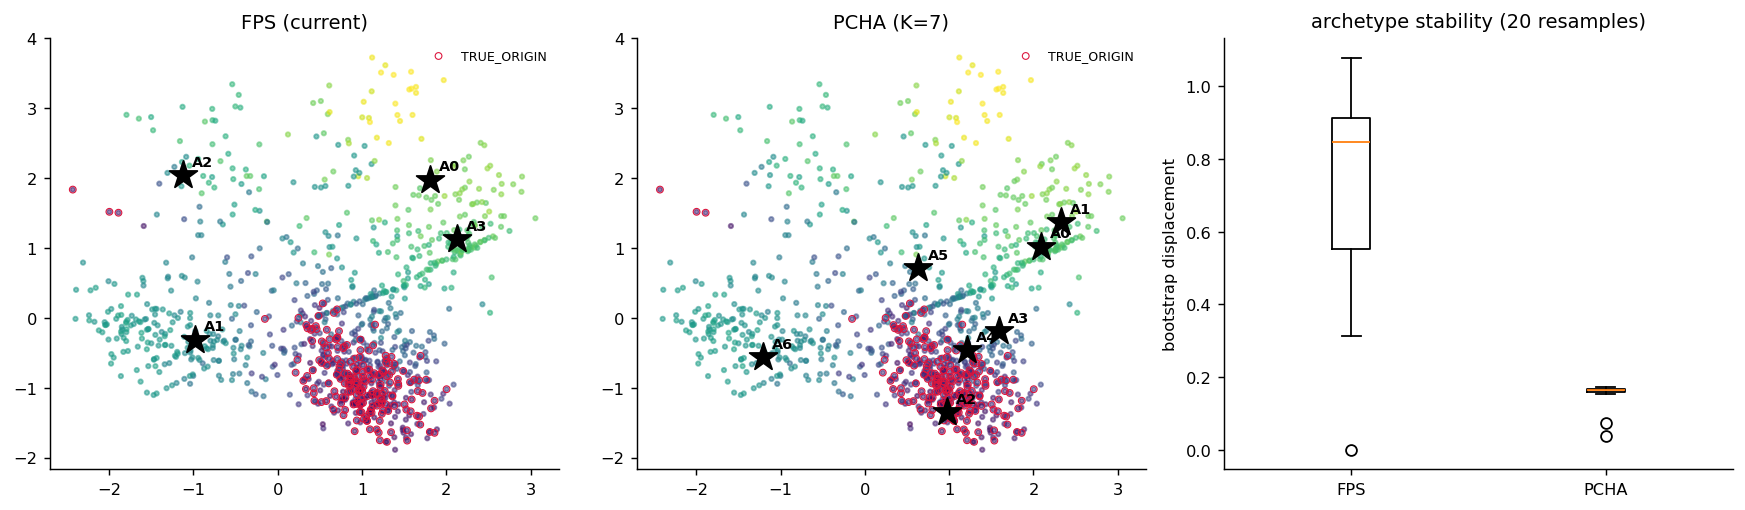

In [12]:
# bootstrap stability: resample 80% of cells, re-fit, measure archetype displacement
def boot_stability(method, n_boot=20):
    ref = Arch_p if method == 'PCHA' else X_pca30[arch_idx_fps]
    scale = np.linalg.norm(X_pca30 - X_pca30.mean(0), axis=1).mean()
    ds = []
    for b in range(n_boot):
        r = np.random.default_rng(b); sub = r.choice(N, int(0.8*N), replace=False)
        if method == 'PCHA':
            A2, _, _, _ = pcha(X_pca30[sub], len(ref), seed=b)
        else:
            ai, _ = fps_archetypes(Z_dec[sub], D_ATOMS, np.array(cell_types)[sub], seed=b)
            A2 = X_pca30[sub][ai]
        # matched distance: each reference archetype to its nearest re-fit archetype
        d = np.linalg.norm(ref[:, None, :] - A2[None, :, :], axis=2).min(1)
        ds.append(d.mean() / scale)
    return np.array(ds)

st_fps, st_pcha = boot_stability('FPS'), boot_stability('PCHA')
print(f"bootstrap displacement (lower=better, units of data radius)")
print(f"  FPS : {st_fps.mean():.3f} ± {st_fps.std():.3f}")
print(f"  PCHA: {st_pcha.mean():.3f} ± {st_pcha.std():.3f}")

fig, ax = plt.subplots(1, 3, figsize=(13.5, 4))
for a, (idxs, nm) in zip(ax[:2], [(arch_idx_fps,'FPS (current)'), (arch_idx_pcha,f'PCHA (K={K_FINAL})')]):
    a.scatter(*V_dec2.T, c=pt, cmap='viridis', s=6, alpha=.55)
    a.scatter(V_dec2[TRUE_ORIGIN,0], V_dec2[TRUE_ORIGIN,1], s=14, facecolors='none',
              edgecolors='crimson', lw=.6, label='TRUE_ORIGIN')
    a.scatter(V_dec2[idxs,0], V_dec2[idxs,1], c='black', marker='*', s=260, zorder=5)
    for j, i in enumerate(idxs):
        a.annotate(f"A{j}", V_dec2[i], fontsize=8, fontweight='bold',
                   xytext=(5,5), textcoords='offset points')
    a.set_title(nm); a.legend(fontsize=7, frameon=False)
ax[2].boxplot([st_fps, st_pcha], labels=['FPS','PCHA'])
ax[2].set_ylabel('bootstrap displacement'); ax[2].set_title('archetype stability (20 resamples)')
plt.tight_layout(); plt.savefig(f"{DIAG}/01_archetypes.png", bbox_inches='tight'); plt.show()

### 1.5 Effect on GRN mixing (Phase-1 reconstruction only)

In [13]:
class GRNDictionary(nn.Module):
    def __init__(s, G, T, M, D):
        super().__init__(); s.D, s.G, s.T = D, G, T
        s.W_raw = nn.Parameter(torch.zeros(D, G, T)); s.W_base = nn.Parameter(torch.zeros(G, T))
        s.register_buffer("M", torch.tensor(M, dtype=torch.float32))
        s.register_buffer("mean_tf", torch.zeros(T))
    @property
    def A_dict(s):  return torch.tanh(s.W_raw) * s.M.unsqueeze(0)
    @property
    def A_base(s):  return torch.tanh(s.W_base) * s.M
    def _atom(s, Xi, w):
        return (torch.einsum('bt,dgt->dbg', Xi, s.A_dict) * w.T.unsqueeze(-1)).sum(0)
    def predict_rna(s, Xtf, w): return (Xtf @ s.A_base.T) + s._atom(Xtf, w)
    def sparsity_loss(s): return s.A_dict.abs().mean() + s.A_base.abs().mean()
    def diversity_loss(s):
        An = F.normalize(s.A_dict.reshape(s.D, -1), dim=1); I = torch.eye(s.D)
        return ((An @ An.T) * (1 - I)).abs().mean()

class CellStateEncoder(nn.Module):
    def __init__(s, G, D, hidden=128):
        super().__init__()
        s.encoder = nn.Sequential(nn.Linear(G, hidden), nn.LayerNorm(hidden), nn.GELU(),
                                  nn.Linear(hidden, hidden//2), nn.GELU())
        s.head = nn.Linear(hidden//2, D)
    def forward(s, x, temperature=1.0):
        return F.softmax(s.head(s.encoder(x)) / temperature, -1)

def masked_recon(grn, w, rna_b, tf_b, tfi, frac=0.40):
    B, Gg = rna_b.shape
    mask = torch.rand(B, Gg) < frac
    tfm = tf_b.clone(); tfm[:, torch.arange(len(tfi))] *= (~mask[:, tfi]).float()
    pred = grn.predict_rna(tfm, w)
    return F.mse_loss(pred[mask], rna_b[mask]) if mask.sum() else pred.mean()*0

def geometric_soft_targets_from_points(Zc, Ac, tau_scale=0.5):
    d2 = ((Zc[:, None, :] - Ac[None, :, :])**2).sum(-1)
    q = np.exp(-d2 / (np.median(d2)*tau_scale + 1e-8))
    return (q / (q.sum(1, keepdims=True) + 1e-8)).astype(np.float32)

def run_grn_phase1(q_target, tag, n_epochs=40, seed=0):
    torch.manual_seed(seed)
    D = q_target.shape[1]
    grn = GRNDictionary(G, len(A_tfs), M, D)
    enc = CellStateEncoder(G, D)
    X_t, XTF_t, q_t = (torch.tensor(X), torch.tensor(X_TF), torch.tensor(q_target))
    grn.mean_tf.copy_(XTF_t.mean(0))
    opt_e = torch.optim.Adam(enc.parameters(), lr=1e-3)
    for _ in range(40):                                   # distil soft targets
        for xb, qb in DataLoader(TensorDataset(X_t, q_t), batch_size=256, shuffle=True):
            lp = F.log_softmax(enc.head(enc.encoder(xb)), -1)
            l = (qb * (torch.log(qb + 1e-8) - lp)).sum(1).mean()
            opt_e.zero_grad(); l.backward(); opt_e.step()
    opt = torch.optim.Adam(list(grn.parameters()) + list(enc.parameters()), lr=1e-3)
    ds = TensorDataset(X_t, XTF_t, torch.arange(N))
    tfi = torch.tensor(tf_indices_in_G)
    hist = []
    for ep in range(n_epochs):
        tot = 0
        for xb, tb, _ in DataLoader(ds, batch_size=512, shuffle=True):
            w = enc(xb)
            l = masked_recon(grn, w, xb, tb, tfi) + 1e-3*grn.sparsity_loss() + 1e-2*grn.diversity_loss()
            opt.zero_grad(); l.backward()
            torch.nn.utils.clip_grad_norm_(list(grn.parameters())+list(enc.parameters()), 1.0)
            opt.step(); tot += float(l)
        hist.append(tot / max(1, N//512))
    with torch.no_grad():
        w_full = enc(X_t).numpy()
        recon  = float(F.mse_loss(grn.predict_rna(XTF_t, enc(X_t)), X_t))
    ent = -(w_full * np.log(w_full + 1e-9)).sum(1)
    print(f"[{tag}] D={D}  final recon MSE={recon:.4f}  mean mixing entropy={ent.mean():.3f}"
          f" / {np.log(D):.3f} max  |  frac cells >0.9 on one atom = {(w_full.max(1)>0.9).mean():.1%}")
    return w_full, ent, recon, hist

q_fps  = geometric_soft_targets_from_points(Z_dec, Z_dec[arch_idx_fps])
q_pcha = geometric_soft_targets_from_points(X_pca30, Arch_p, tau_scale=1.5)
w_fps,  e_fps,  r_fps,  h_fps  = run_grn_phase1(q_fps,  'FPS')
w_pcha, e_pcha, r_pcha, h_pcha = run_grn_phase1(q_pcha, 'PCHA')

[FPS] D=4  final recon MSE=0.2362  mean mixing entropy=0.199 / 1.386 max  |  frac cells >0.9 on one atom = 79.4%
[PCHA] D=7  final recon MSE=0.2335  mean mixing entropy=0.191 / 1.946 max  |  frac cells >0.9 on one atom = 82.2%


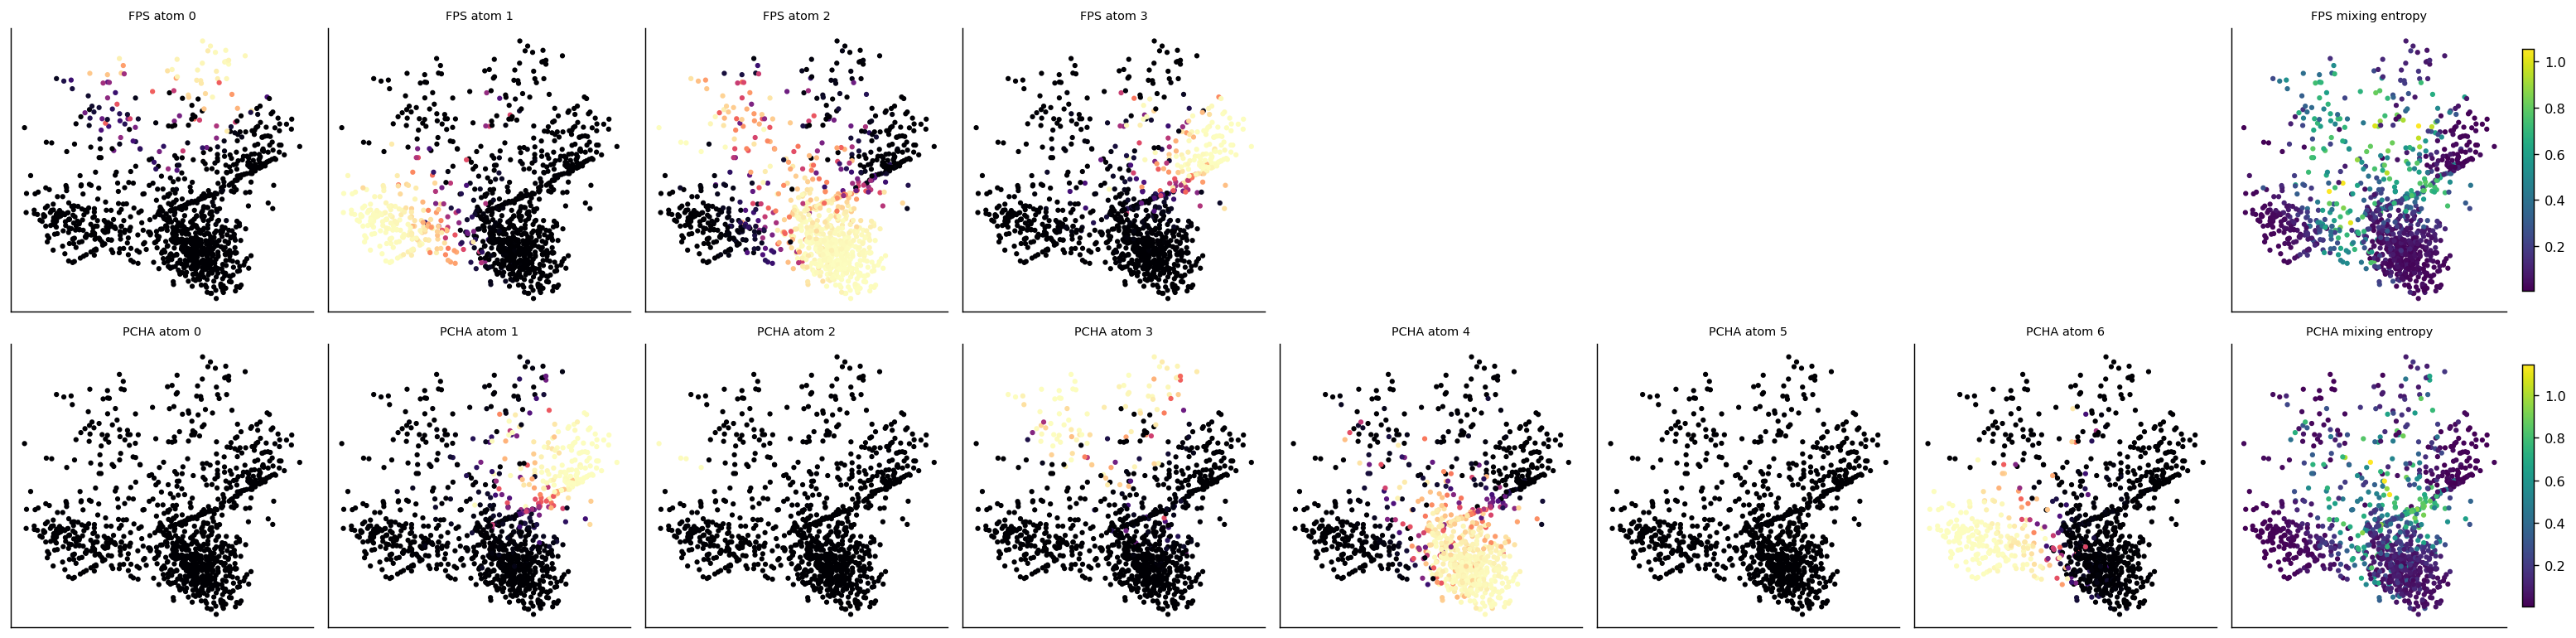

FPS: entropy AUROC for TRUE_ORIGIN = 0.310 | for CENTER = 0.640 | Spearman vs pt = +0.283
PCHA: entropy AUROC for TRUE_ORIGIN = 0.488 | for CENTER = 0.776 | Spearman vs pt = -0.144


In [14]:
fig, ax = plt.subplots(2, max(w_fps.shape[1], w_pcha.shape[1]) + 1,
                       figsize=(3*(max(w_fps.shape[1], w_pcha.shape[1])+1), 6))
for row, (w, e, nm) in enumerate([(w_fps, e_fps, 'FPS'), (w_pcha, e_pcha, 'PCHA')]):
    for d in range(w.shape[1]):
        s = ax[row, d].scatter(*V_dec2.T, c=w[:, d], cmap='magma', s=6, vmin=0, vmax=1)
        ax[row, d].set_title(f"{nm} atom {d}", fontsize=8)
    for d in range(w.shape[1], ax.shape[1]-1): ax[row, d].axis('off')
    sm = ax[row, -1].scatter(*V_dec2.T, c=e, cmap='viridis', s=6)
    plt.colorbar(sm, ax=ax[row, -1], fraction=.04)
    ax[row, -1].set_title(f"{nm} mixing entropy", fontsize=8)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(f"{DIAG}/01_grn_mixing.png", bbox_inches='tight'); plt.show()

for nm, e in [('FPS', e_fps), ('PCHA', e_pcha)]:
    print(f"{nm}: entropy AUROC for TRUE_ORIGIN = {roc_auc_score(TRUE_ORIGIN, e):.3f} | "
          f"for CENTER = {roc_auc_score(CENTER, e):.3f} | Spearman vs pt = {spearmanr(e, pt).correlation:+.3f}")

**Read:** if `entropy AUROC for CENTER` ≫ `for TRUE_ORIGIN` under both archetype schemes, mixing
entropy is confirmed as a hub detector and must be permanently removed from origin logic
(this is the §5 hypothesis, tested).

---

## Experiment 2 — Do the gene-space displacements mean anything?

We build a **reference displacement field** from the smoothed pseudotime by local weighted
least squares: for cell *i* with neighbours *j*,

```
v_ref(i) = Σ_j (pt_j − pt_i)(x_j − x_i) / Σ_j (pt_j − pt_i)²
```

This is the empirical dX/dt on the manifold — the vector a perfect velocity method would
return. We then score `V_pred` against it, and against two nulls: a **radial** field
(away from the population mean, the known artifact) and a **shuffled** field.

In [16]:
V_pred = np.load("bert_grn_out_working_new6/V_pred.npy")   # <-- point at your run
print("V_pred", V_pred.shape)

# reproduce the exact space V_pred lives in
def build_local_atac(X_rna, ga, cluster_space, n_clusters=40, k_atac=8, n_match_pcs=20,
                     seed=42, feat=None):
    Gl = X_rna.shape[1]
    fs = np.arange(Gl) if feat is None else feat
    km = MiniBatchKMeans(n_clusters=n_clusters, random_state=seed, n_init=5)
    lab = km.fit_predict(cluster_space)
    cr_full = np.stack([X_rna[lab == c].mean(0) if (lab == c).any() else np.zeros(Gl)
                        for c in range(n_clusters)]).astype(np.float32)
    cr, gaf = normalize(cr_full[:, fs], norm='l2'), normalize(ga[:, fs], norm='l2')
    npc = int(min(n_match_pcs, cr.shape[0]-1, gaf.shape[0]-1, len(fs)-1))
    p = PCA(n_components=npc, random_state=seed).fit(np.vstack([cr, gaf]))
    _, aidx = NearestNeighbors(n_neighbors=k_atac).fit(
        normalize(p.transform(gaf), norm='l2')).kneighbors(normalize(p.transform(cr), norm='l2'))
    ca = np.stack([ga[aidx[c]].mean(0) for c in range(n_clusters)])
    loc = ca[lab]
    lo, hi = loc.min(0, keepdims=True), loc.max(0, keepdims=True)
    return ((loc - lo) / (hi - lo + 1e-8)).astype(np.float32), lab, aidx

local_access, km_lab, km_aidx = build_local_atac(X, gene_activity, Z_dec,
                                                 n_match_pcs=N_MATCH_PCS)
atac_z = zscore_cols(knn_smooth(local_access, k=K_MOMENT))
rna_z  = zscore_cols(knn_smooth(X,            k=K_MOMENT))
lead   = knn_smooth((atac_z - rna_z).astype(np.float32), k=K_MOMENT)
print(f"per-gene ATAC-RNA rho: mean={float((atac_z*rna_z).mean()):.3f}")

V_pred (1035, 3016)
per-gene ATAC-RNA rho: mean=0.027


In [17]:
def reference_velocity(coords, pt_vec, nb=NB, k=30):
    """local WLS slope d(coords)/d(pt)."""
    out = np.zeros_like(coords, dtype=np.float32)
    for i in range(len(coords)):
        j  = nb[i, :k]
        dt = pt_vec[j] - pt_vec[i]
        den = float((dt**2).sum())
        if den < 1e-10: continue
        out[i] = (dt[:, None] * (coords[j] - coords[i])).sum(0) / den
    return out

V_ref_hi = reference_velocity(rna_z,  pt)     # gene space, same units as V_pred
V_ref_2d = reference_velocity(V_dec2, pt)     # 2D space
V_rad    = rna_z.copy()                       # radial null
V_shuf   = V_pred[rng.permutation(N)]         # shuffled null

rows = []
for nm, Vv in [('V_pred', V_pred), ('radial null', V_rad), ('shuffled null', V_shuf),
               ('raw lead', lead), ('V_ref (self)', V_ref_hi)]:
    c = cos_rows(Vv, V_ref_hi)
    rows.append(dict(field=nm, cos_all=np.nanmean(c),
                     cos_early=np.nanmean(c[EARLY]), cos_late=np.nanmean(c[LATE]),
                     frac_pos=np.nanmean(c > 0),
                     cos_with_radial=np.nanmean(cos_rows(Vv, V_rad))))
R2 = pd.DataFrame(rows)
print(R2.to_string(index=False, float_format=lambda v: f"{v:+.3f}"))

        field  cos_all  cos_early  cos_late  frac_pos  cos_with_radial
       V_pred   +0.023     +0.008    +0.067    +0.688           +0.008
  radial null   +0.185     -0.243    +0.229    +0.629           +1.000
shuffled null   +0.002     +0.001    -0.002    +0.502           +0.004
     raw lead   -0.085     +0.166    -0.102    +0.382           -0.580
 V_ref (self)   +1.000     +1.000    +1.000    +1.000           +0.185


**Read:** `cos_all` for `V_pred` is the headline. If it is ≈0 while `cos_with_radial` is large,
the field is the artifact, not the derivative. The `radial null` row is the bar to beat — any
method scoring at or below it has added nothing.

### 2.1 CBDir / ICCoh (the metrics reviewers expect)

`CBDir` and `ICCoh` are the standard RNA-velocity accuracy metrics from VeloAE, used in every
recent benchmark. CBDir asks: at a boundary between a source and target cluster, do the source
cells' velocities point at the target cells?

In [18]:
LINEAGE = [('HSC','MPP'), ('MPP','CMP'), ('MPP','MLP'), ('CMP','GMP'), ('CMP','MEP')]

def project_to_2d(V, X2, Xh, search_space=None, k=30, scale=1.0, drift_correct=True):
    ss = X2 if search_space is None else search_space
    _, idx = NearestNeighbors(n_neighbors=k).fit(ss).kneighbors(ss)
    dh, dl = Xh[idx] - Xh[:, None, :], X2[idx] - X2[:, None, :]
    sims = np.einsum('ng,nkg->nk', V, dh) / ((np.linalg.norm(dh, axis=2) + 1e-8) *
                                             (np.linalg.norm(V, axis=1, keepdims=True) + 1e-8))
    sims -= sims.mean(1, keepdims=True)
    w = np.exp(sims * scale); w /= (w.sum(1, keepdims=True) + 1e-8)
    if drift_correct: w = w - 1.0/k
    E = np.einsum('nk,nkd->nd', w, dl / (np.linalg.norm(dl, axis=2, keepdims=True) + 1e-8))
    sp = np.linalg.norm(V, axis=1); sp = sp / (np.percentile(sp, 95) + 1e-8)
    return (E * sp[:, None]).astype(np.float32)

def cbdir(V2, labels, edges, nb=NB, k=20):
    out = {}
    for a, b in edges:
        src = np.where(np.array(labels) == a)[0]
        cs = []
        for i in src:
            tgt = [j for j in nb[i, :k] if labels[j] == b]
            if not tgt: continue
            d = unit(V_dec2[tgt] - V_dec2[i], 1)
            cs.append(float((unit(V2[i:i+1], 1) * d).sum(1).mean()))
        out[f"{a}->{b}"] = (np.mean(cs) if cs else np.nan, len(cs))
    return out

def iccoh(V2, labels, nb=NB, k=20):
    cs = []
    for i in range(len(V2)):
        j = [x for x in nb[i, :k] if labels[x] == labels[i] and x != i]
        if j: cs.append(float((unit(V2[i:i+1],1) * unit(V2[j],1)).sum(1).mean()))
    return float(np.mean(cs))

fields = {'V_pred': V_pred, 'radial null': V_rad, 'raw lead': lead, 'V_ref (oracle)': V_ref_hi}
P2 = {nm: project_to_2d(v, V_dec2, rna_z, search_space=Z_dec, k=20) for nm, v in fields.items()}
cb = pd.DataFrame({nm: {k_: v_[0] for k_, v_ in cbdir(p, cell_types, LINEAGE).items()}
                   for nm, p in P2.items()})
cb.loc['MEAN'] = cb.mean()
cb.loc['ICCoh'] = [iccoh(p, cell_types) for p in P2.values()]
print(cb.to_string(float_format=lambda v: f"{v:+.3f}"))

          V_pred  radial null  raw lead  V_ref (oracle)
HSC->MPP  +0.010       -0.483    +0.191          -0.166
MPP->CMP  +0.024       -0.407    +0.127          +0.072
MPP->MLP  -0.112       -0.440    +0.191          -0.123
CMP->GMP  +0.278       -0.218    +0.164          +0.268
CMP->MEP  -0.185       -0.093    +0.060          -0.164
MEAN      +0.003       -0.328    +0.146          -0.022
ICCoh     +0.444       +0.172    +0.120          +0.523


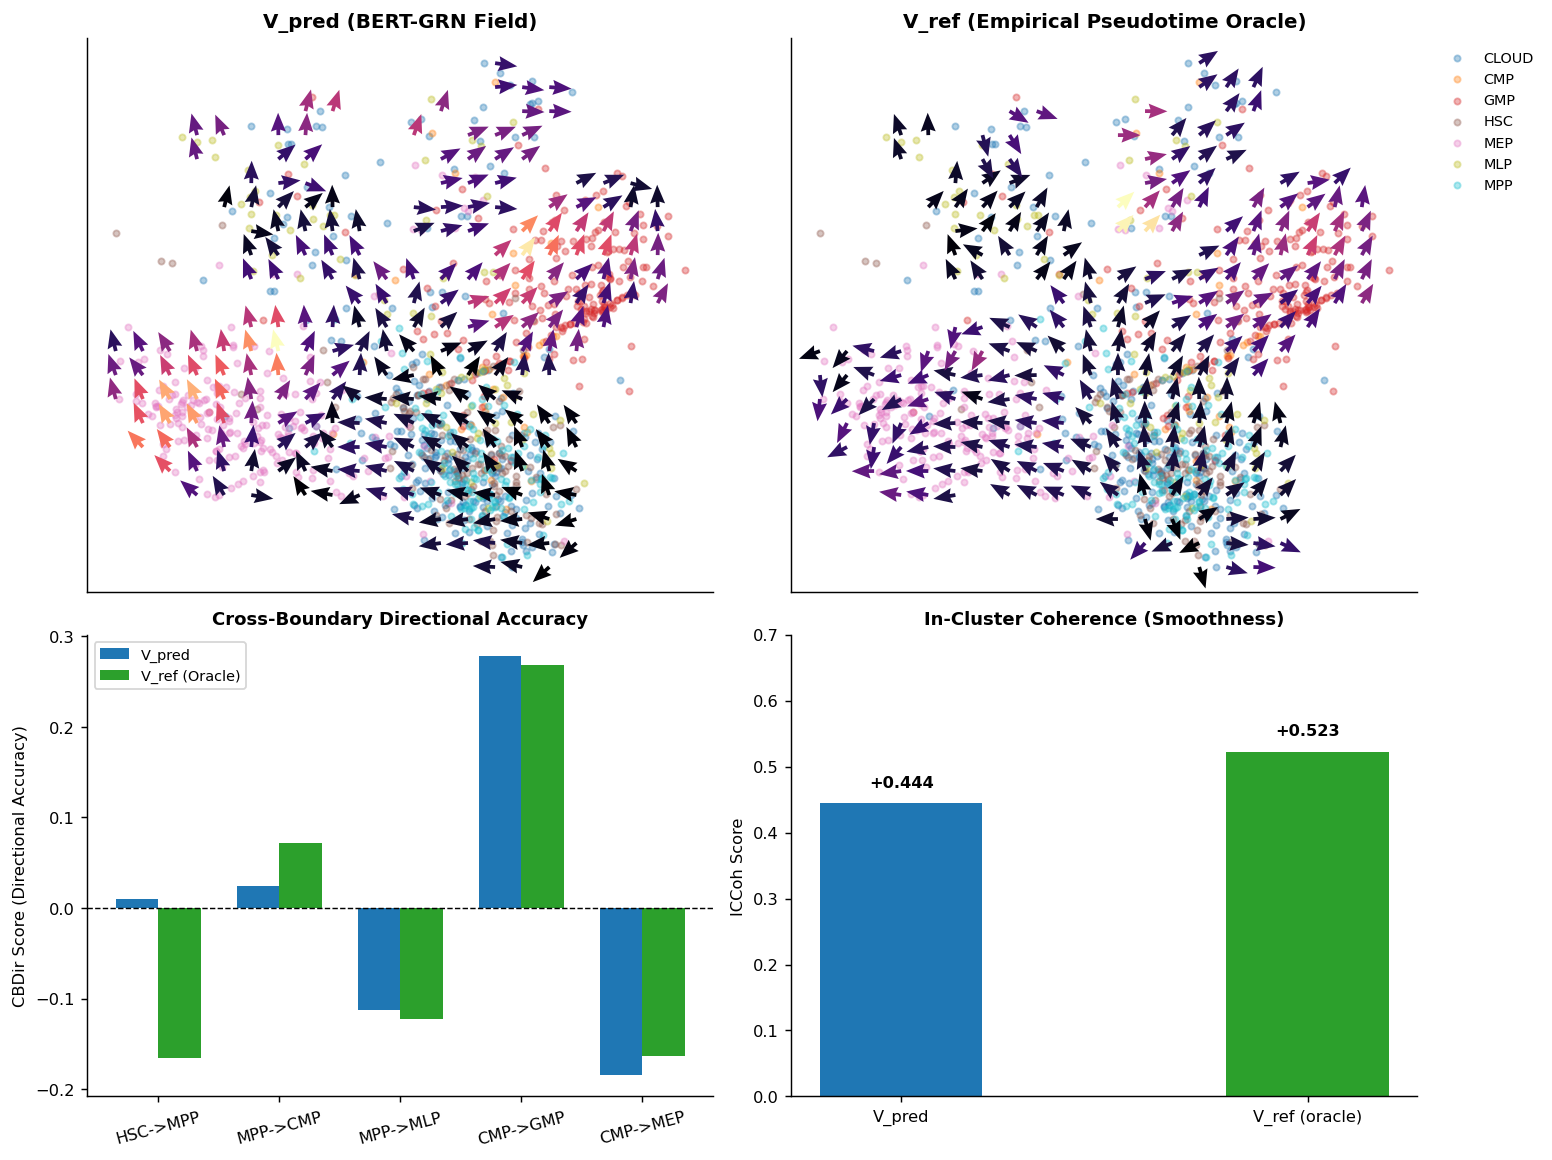

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Define target fields to evaluate
target_fields = {
    'V_pred (BERT-GRN)': P2['V_pred'],
    'V_ref (Oracle)': P2['V_ref (oracle)']
}

# Define color palette for cell types
unique_cts = np.unique(cell_types)
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_cts)))
ct_to_color = dict(zip(unique_cts, colors))

fig = plt.figure(figsize=(12, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[1.2, 1])

# --- 1. Top Row: Quiver Plots for V_pred and V_ref ---
def plot_clean_quiver(ax, V2D, title):
    # Scatter plot of background cell types
    for ct in unique_cts:
        m = cell_types == ct
        ax.scatter(V_dec2[m, 0], V_dec2[m, 1], c=[ct_to_color[ct]], s=12, alpha=0.35, label=ct)
    
    # Coarse grid for arrows
    n_grid = 22
    x_min, x_max = V_dec2[:, 0].min(), V_dec2[:, 0].max()
    y_min, y_max = V_dec2[:, 1].min(), V_dec2[:, 1].max()
    x_grid = np.linspace(x_min, x_max, n_grid)
    y_grid = np.linspace(y_min, y_max, n_grid)
    
    grid_x, grid_y, grid_u, grid_v = [], [], [], []
    for xi in x_grid:
        for yi in y_grid:
            dist = np.sqrt((V_dec2[:, 0] - xi)**2 + (V_dec2[:, 1] - yi)**2)
            near = dist < (x_max - x_min) / n_grid * 1.2
            if near.sum() > 3:
                grid_x.append(xi); grid_y.append(yi)
                grid_u.append(V2D[near, 0].mean())
                grid_v.append(V2D[near, 1].mean())
                
    u, v = np.array(grid_u), np.array(grid_v)
    speed = np.sqrt(u**2 + v**2) + 1e-8
    
    ax.quiver(grid_x, grid_y, u/speed, v/speed, speed, cmap='magma', scale=28, width=0.006, headwidth=4)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])

ax_pred = fig.add_subplot(gs[0, 0])
plot_clean_quiver(ax_pred, target_fields['V_pred (BERT-GRN)'], 'V_pred (BERT-GRN Field)')

ax_ref = fig.add_subplot(gs[0, 1])
plot_clean_quiver(ax_ref, target_fields['V_ref (Oracle)'], 'V_ref (Empirical Pseudotime Oracle)')
ax_ref.legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False, fontsize=8)


# --- 2. Bottom Left: CBDir Comparison Across Transitions ---
ax_cb = fig.add_subplot(gs[1, 0])
cb_sub = cb[['V_pred', 'V_ref (oracle)']].drop(index=['MEAN', 'ICCoh'])

x = np.arange(len(cb_sub))
width = 0.35

ax_cb.bar(x - width/2, cb_sub['V_pred'], width, label='V_pred', color='#1f77b4')
ax_cb.bar(x + width/2, cb_sub['V_ref (oracle)'], width, label='V_ref (Oracle)', color='#2ca02c')

ax_cb.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax_cb.set_xticks(x)
ax_cb.set_xticklabels(cb_sub.index, rotation=15, fontsize=9)
ax_cb.set_ylabel('CBDir Score (Directional Accuracy)')
ax_cb.set_title('Cross-Boundary Directional Accuracy', fontsize=10, fontweight='bold')
ax_cb.legend(fontsize=8)


# --- 3. Bottom Right: In-Cluster Coherence (ICCoh) ---
ax_ic = fig.add_subplot(gs[1, 1])
ic_sub = cb[['V_pred', 'V_ref (oracle)']].loc['ICCoh']

bars = ax_ic.bar(ic_sub.index, ic_sub.values, width=0.4, color=['#1f77b4', '#2ca02c'])
ax_ic.set_ylabel('ICCoh Score')
ax_ic.set_title('In-Cluster Coherence (Smoothness)', fontsize=10, fontweight='bold')
ax_ic.set_ylim(0, 0.7)

for bar in bars:
    yval = bar.get_height()
    ax_ic.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f"{yval:+.3f}", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(f"{DIAG}/02_vpred_vs_vref_comparison.png", bbox_inches='tight', dpi=300)
plt.show()

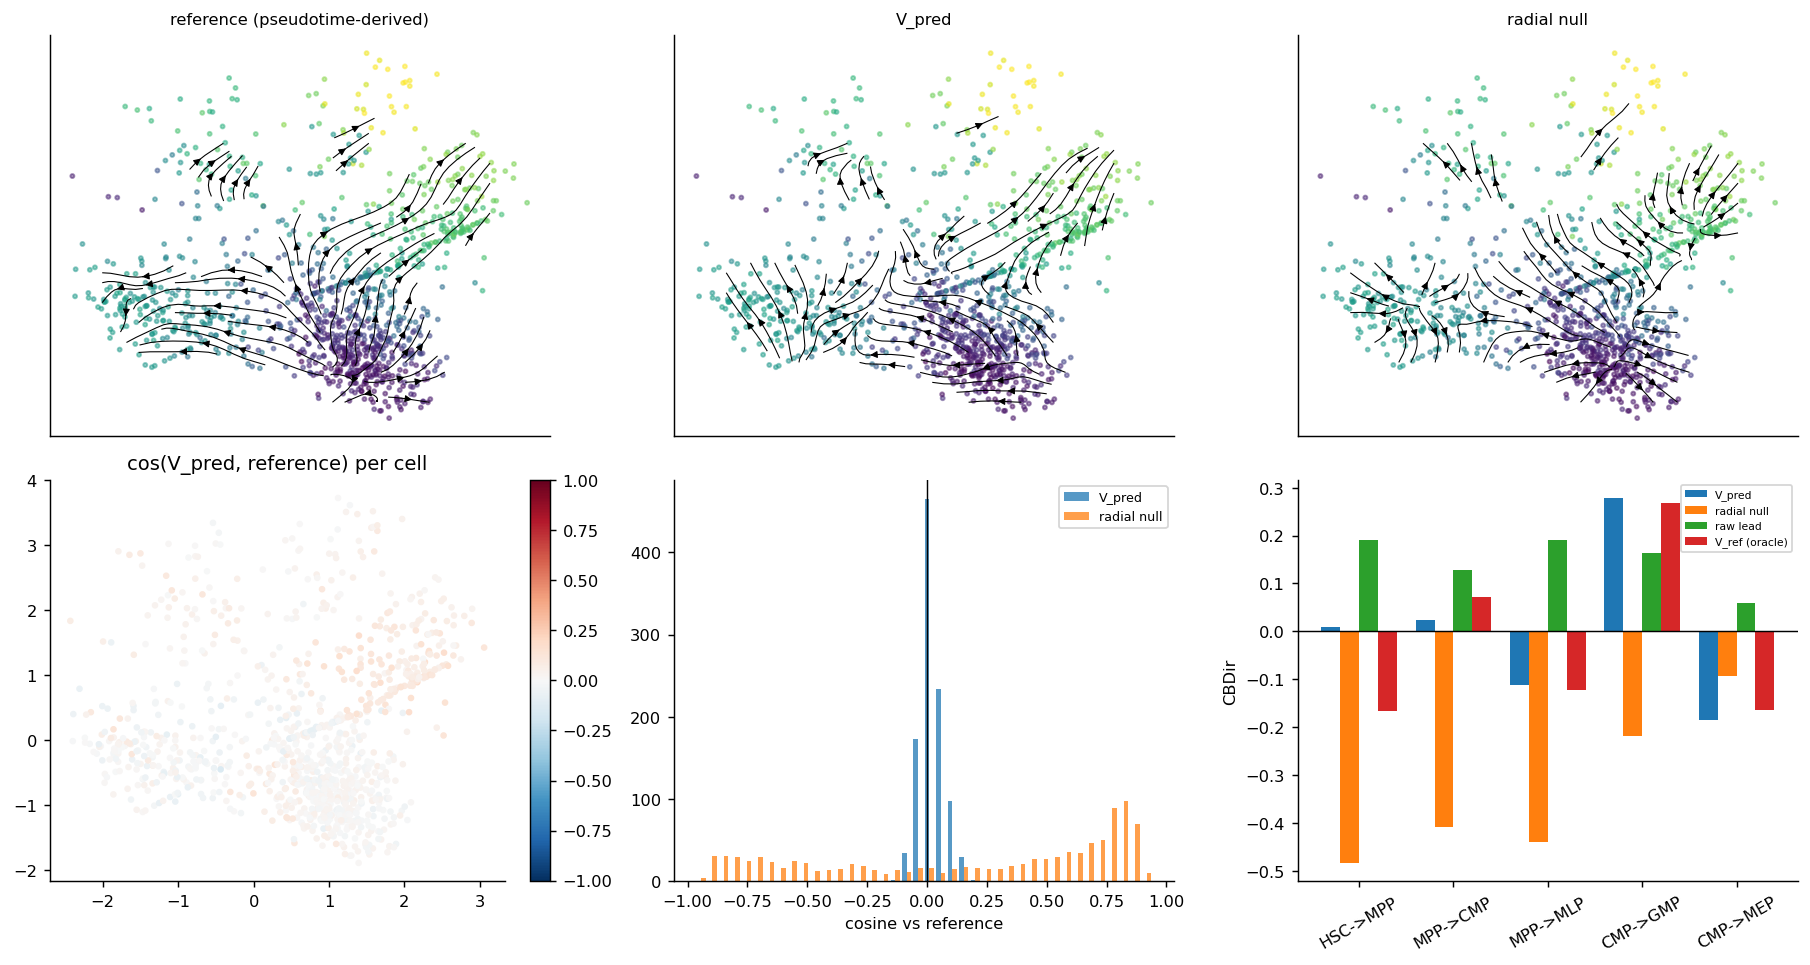

In [19]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7.5))
def stream(a, V2, title):
    a.scatter(*V_dec2.T, c=pt, cmap='viridis', s=5, alpha=.5)
    gx, gy = np.meshgrid(np.linspace(*np.percentile(V_dec2[:,0], [1,99]), 28),
                         np.linspace(*np.percentile(V_dec2[:,1], [1,99]), 28))
    gp = np.c_[gx.ravel(), gy.ravel()]
    dd, gi = NearestNeighbors(n_neighbors=15).fit(V_dec2).kneighbors(gp)
    Vg = V2[gi].mean(1); Vg[dd.mean(1) > np.percentile(dd.mean(1), 55)] = np.nan
    a.streamplot(gx, gy, Vg[:,0].reshape(gx.shape), Vg[:,1].reshape(gx.shape),
                 color='k', density=1.1, linewidth=.6, arrowsize=.8)
    a.set_title(title, fontsize=9); a.set_xticks([]); a.set_yticks([])

stream(ax[0,0], P2['V_ref (oracle)'], 'reference (pseudotime-derived)')
stream(ax[0,1], P2['V_pred'],         'V_pred')
stream(ax[0,2], P2['radial null'],    'radial null')
c_pred = cos_rows(V_pred, V_ref_hi)
s = ax[1,0].scatter(*V_dec2.T, c=c_pred, cmap='RdBu_r', vmin=-1, vmax=1, s=7)
plt.colorbar(s, ax=ax[1,0], fraction=.04); ax[1,0].set_title('cos(V_pred, reference) per cell')
ax[1,1].hist([cos_rows(V_pred, V_ref_hi), cos_rows(V_rad, V_ref_hi)], bins=40,
             label=['V_pred','radial null'], alpha=.75)
ax[1,1].axvline(0, c='k', lw=.8); ax[1,1].legend(fontsize=7); ax[1,1].set_xlabel('cosine vs reference')
cbm = cb.drop(index=['MEAN','ICCoh'])
cbm.plot(kind='bar', ax=ax[1,2], width=.8); ax[1,2].axhline(0, c='k', lw=.8)
ax[1,2].set_ylabel('CBDir'); ax[1,2].legend(fontsize=6); ax[1,2].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig(f"{DIAG}/02_displacement_eval.png", bbox_inches='tight'); plt.show()

---

## Experiment 3 — Is the projection faithful?

The confusion is real: there is no canonical gene-space vector that means "up in 2D", because
2D coordinates are a nonlinear function of gene space. The resolution: **only directions that
lie in the span of actual neighbour displacements are meaningful on the manifold.** So we
construct the test field as a combination of real neighbour differences, chosen so its exact
pushforward to 2D is a target vector `u` we specify.

For cell *i*, let `Dhi = X[nb] − X[i]` (k×G) and `Dlo = Y[nb] − Y[i]` (k×2). Pick minimum-norm
coefficients `c` with `Dloᵀ c = u`:

```
c = Dlo (Dloᵀ Dlo)⁻¹ u        v_i = Dhiᵀ c
```

Then `v_i` is a genuine tangent vector whose true 2D image is exactly `u`. Any deviation of
`project_to_2d(v)` from `u` is projection error, measured in degrees.

In [22]:
def pullback_field(u_of_cell, k=30, nb=NB, ref_hi=None, ref_lo=None):
    """Return gene-space V whose exact local pushforward is u_of_cell(i)."""
    Xh = rna_z if ref_hi is None else ref_hi
    Yl = V_dec2 if ref_lo is None else ref_lo
    V = np.zeros((len(Xh), Xh.shape[1]), np.float32)
    U = np.zeros((len(Xh), 2), np.float32)
    for i in range(len(Xh)):
        j = nb[i, 1:k]
        Dlo, Dhi = Yl[j] - Yl[i], Xh[j] - Xh[i]
        u = np.asarray(u_of_cell(i), np.float32); U[i] = u
        Gm = Dlo.T @ Dlo
        c  = Dlo @ np.linalg.solve(Gm + 1e-8*np.eye(2), u)
        V[i] = Dhi.T @ c
    return V, U

def ang_err(A, B):
    c = np.clip((unit(A,1) * unit(B,1)).sum(1), -1, 1)
    return np.degrees(np.arccos(c))

# --- the five test fields ---
grad2 = reference_velocity(V_dec2, pt)          # true 2D pseudotime gradient
tests = {}
tests['constant up']      = pullback_field(lambda i: np.array([0., 1.]))
tests['constant right']   = pullback_field(lambda i: np.array([1., 0.]))
tests['rotational']       = pullback_field(lambda i: unit(np.array([-(V_dec2[i,1]-cen[1]),
                                                                     (V_dec2[i,0]-cen[0])]), 0))
tests['radial out']       = pullback_field(lambda i: unit(V_dec2[i] - cen, 0))
tests['pseudotime grad']  = pullback_field(lambda i: unit(grad2[i], 0) if np.linalg.norm(grad2[i])>0
                                                     else np.array([0.,0.]))

res = []
for nm, (Vg, U) in tests.items():
    Pj = project_to_2d(Vg, V_dec2, rna_z, search_space=Z_dec, k=20, scale=1.0)
    e  = ang_err(Pj, U)
    Pn = project_to_2d(-Vg, V_dec2, rna_z, search_space=Z_dec, k=20, scale=1.0)
    res.append(dict(field=nm, median_deg=np.nanmedian(e), p90_deg=np.nanpercentile(e, 90),
                    frac_within_30=np.nanmean(e < 30),
                    reversal_cos=np.nanmean(cos_rows(Pn, -Pj))))
# noise null: should project to near-zero magnitude
V_noise = rng.standard_normal((N, G)).astype(np.float32)
P_noise = project_to_2d(V_noise, V_dec2, rna_z, search_space=Z_dec, k=20)
P_sig   = project_to_2d(tests['pseudotime grad'][0], V_dec2, rna_z, search_space=Z_dec, k=20)
res.append(dict(field='gaussian noise', median_deg=np.nan, p90_deg=np.nan,
                frac_within_30=np.nan, reversal_cos=np.nan))
T3 = pd.DataFrame(res)
print(T3.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print(f"\nnoise |P| / signal |P| = "
      f"{np.linalg.norm(P_noise,axis=1).mean()/np.linalg.norm(P_sig,axis=1).mean():.3f}  (want << 1)")

          field  median_deg  p90_deg  frac_within_30  reversal_cos
    constant up      16.276   44.925           0.772         0.991
 constant right      14.735   42.249           0.803         0.988
     rotational      16.580   43.652           0.757         0.988
     radial out      13.192   37.309           0.827         0.991
pseudotime grad      12.630   35.118           0.856         0.992
 gaussian noise         NaN      NaN             NaN           NaN

noise |P| / signal |P| = 0.072  (want << 1)


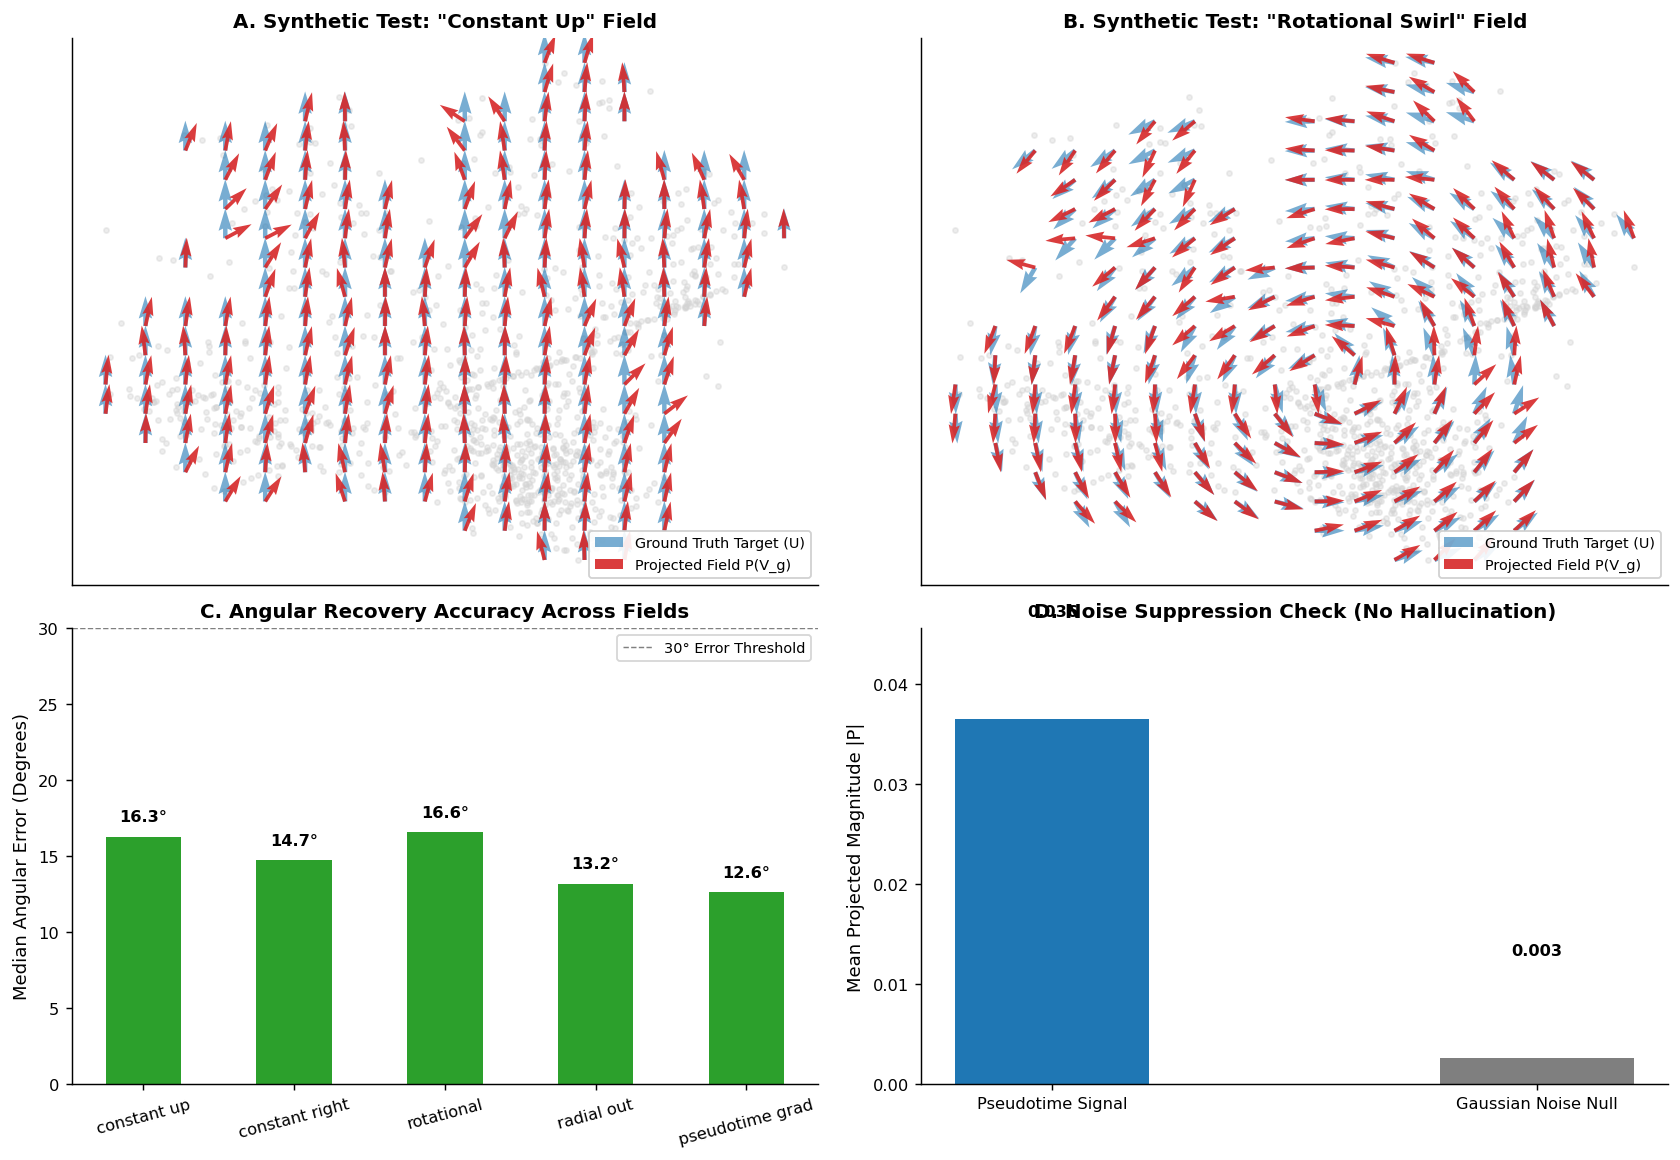

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Set up Layout ---
fig = plt.figure(figsize=(13, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[1.2, 1])

# --- 2. Function to Plot Synthetic Overlay (Ground Truth vs Projected) ---
def plot_projection_calibration(ax, test_name, title):
    Vg, U_gt = tests[test_name]
    Pj = project_to_2d(Vg, V_dec2, rna_z, search_space=Z_dec, k=20, scale=1.0)
    
    # Background cells in faint gray
    ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c='lightgray', s=8, alpha=0.4, zorder=1)
    
    # Coarse grid for arrows
    n_grid = 18
    x_min, x_max = V_dec2[:, 0].min(), V_dec2[:, 0].max()
    y_min, y_max = V_dec2[:, 1].min(), V_dec2[:, 1].max()
    x_grid = np.linspace(x_min, x_max, n_grid)
    y_grid = np.linspace(y_min, y_max, n_grid)
    
    grid_x, grid_y = [], []
    u_gt_list, v_gt_list = [], []
    u_pj_list, v_pj_list = [], []
    
    for xi in x_grid:
        for yi in y_grid:
            dist = np.sqrt((V_dec2[:, 0] - xi)**2 + (V_dec2[:, 1] - yi)**2)
            near = dist < (x_max - x_min) / n_grid * 1.2
            if near.sum() > 3:
                grid_x.append(xi); grid_y.append(yi)
                u_gt_list.append(U_gt[near, 0].mean())
                v_gt_list.append(U_gt[near, 1].mean())
                u_pj_list.append(Pj[near, 0].mean())
                v_pj_list.append(Pj[near, 1].mean())
                
    # Normalize for clean display
    u_gt, v_gt = np.array(u_gt_list), np.array(v_gt_list)
    u_pj, v_pj = np.array(u_pj_list), np.array(v_pj_list)
    
    sp_gt = np.sqrt(u_gt**2 + v_gt**2) + 1e-8
    sp_pj = np.sqrt(u_pj**2 + v_pj**2) + 1e-8
    
    # Plot Ground Truth (Blue)
    ax.quiver(grid_x, grid_y, u_gt/sp_gt, v_gt/sp_gt, color='#1f77b4', 
              scale=25, width=0.006, alpha=0.6, label='Ground Truth Target (U)', zorder=2)
    # Plot Projected Field (Red)
    ax.quiver(grid_x, grid_y, u_pj/sp_pj, v_pj/sp_pj, color='#d62728', 
              scale=25, width=0.005, alpha=0.9, label='Projected Field P(V_g)', zorder=3)
    
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])
    ax.legend(loc='lower right', fontsize=8, framealpha=0.9)

# Draw Panels A & B: Two visual examples
ax_a = fig.add_subplot(gs[0, 0])
plot_projection_calibration(ax_a, 'constant up', 'A. Synthetic Test: "Constant Up" Field')

ax_b = fig.add_subplot(gs[0, 1])
plot_projection_calibration(ax_b, 'rotational', 'B. Synthetic Test: "Rotational Swirl" Field')

# --- 3. Panel C: Angular Error Summary ---
ax_c = fig.add_subplot(gs[1, 0])
fields_to_plot = T3.dropna(subset=['median_deg'])

x = np.arange(len(fields_to_plot))
bars = ax_c.bar(x, fields_to_plot['median_deg'], color='#2ca02c', width=0.5)

ax_c.set_ylabel('Median Angular Error (Degrees)', fontsize=10)
ax_c.set_title('C. Angular Recovery Accuracy Across Fields', fontsize=11, fontweight='bold')
ax_c.set_xticks(x)
ax_c.set_xticklabels(fields_to_plot['field'], rotation=15, fontsize=9)
ax_c.set_ylim(0, 30)
ax_c.axhline(30, color='gray', linestyle='--', linewidth=0.8, label='30° Error Threshold')

for bar in bars:
    yval = bar.get_height()
    ax_c.text(bar.get_x() + bar.get_width()/2, yval + 0.8, f"{yval:.1f}°", 
              ha='center', va='bottom', fontsize=9, fontweight='bold')

ax_c.legend(fontsize=8, loc='upper right')

# --- 4. Panel D: Noise Suppression ---
ax_d = fig.add_subplot(gs[1, 1])
# Magnitude comparison between Signal and Noise
P_sig_mag = np.linalg.norm(P_sig, axis=1).mean()
P_noise_mag = np.linalg.norm(P_noise, axis=1).mean()

bars_d = ax_d.bar(['Pseudotime Signal', 'Gaussian Noise Null'], [P_sig_mag, P_noise_mag], 
                  color=['#1f77b4', '#7f7f7f'], width=0.4)

ax_d.set_ylabel('Mean Projected Magnitude |P|', fontsize=10)
ax_d.set_title('D. Noise Suppression Check (No Hallucination)', fontsize=11, fontweight='bold')

for bar in bars_d:
    yval = bar.get_height()
    ax_d.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval:.3f}", 
              ha='center', va='bottom', fontsize=9, fontweight='bold')

ax_d.set_ylim(0, max(P_sig_mag, P_noise_mag) * 1.25)

plt.tight_layout()
plt.savefig(f"{DIAG}/03_projection_calibration_dashboard.png", bbox_inches='tight', dpi=300)
plt.show()

Three properties are being checked, each with a hard target:

- **fidelity** — `median_deg` should be < 20° (the projection recovers a known answer),
- **antisymmetry** — `reversal_cos` must be ≈ −1 (projecting `−v` gives `−P(v)`; anything else
  means the kernel injects a direction of its own),
- **null rejection** — noise must project to near-zero magnitude, not to the density gradient.

### 3.1 Parameter sweep

best: k=30, scale=4.0  → median error 11.0°


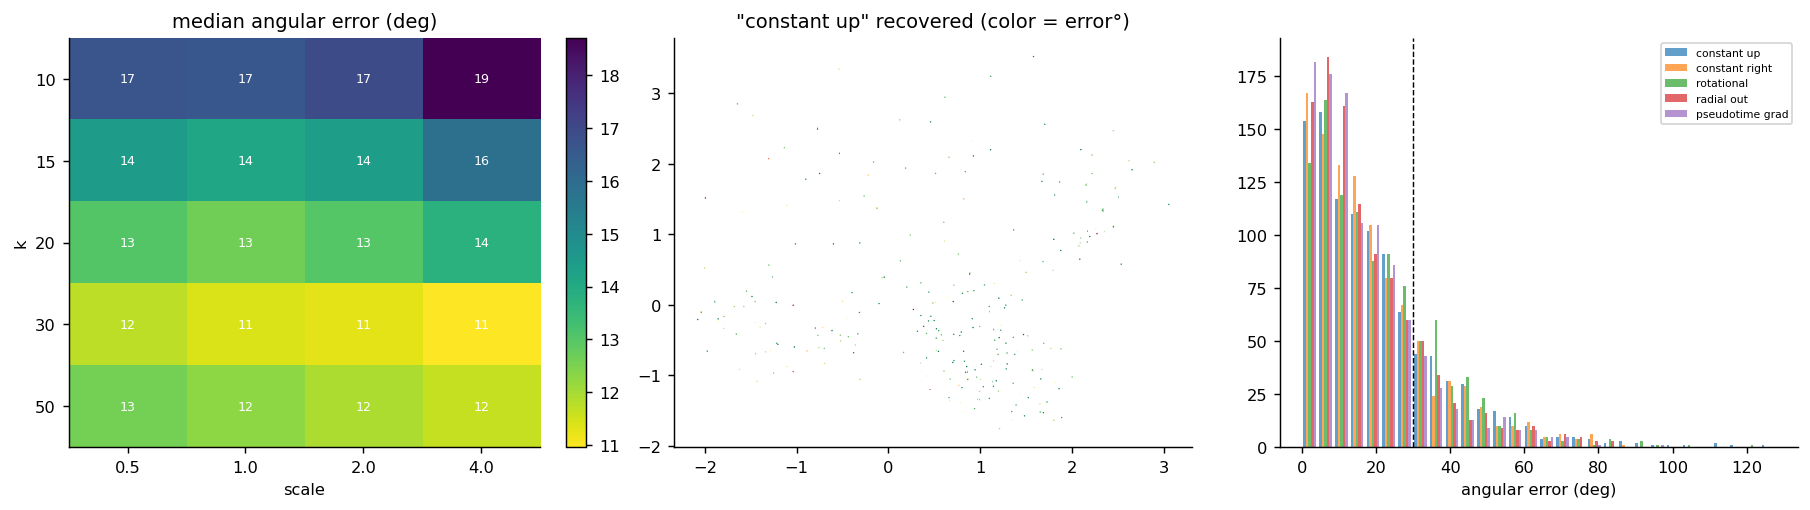

In [24]:
Vg, U = tests['pseudotime grad']
ks, scales = [10, 15, 20, 30, 50], [0.5, 1.0, 2.0, 4.0]
H = np.zeros((len(ks), len(scales)))
for a, k_ in enumerate(ks):
    for b, s_ in enumerate(scales):
        H[a, b] = np.nanmedian(ang_err(
            project_to_2d(Vg, V_dec2, rna_z, search_space=Z_dec, k=k_, scale=s_), U))
best = np.unravel_index(np.argmin(H), H.shape)
print(f"best: k={ks[best[0]]}, scale={scales[best[1]]}  → median error {H[best]:.1f}°")

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
im = ax[0].imshow(H, cmap='viridis_r', aspect='auto')
ax[0].set_xticks(range(len(scales)), scales); ax[0].set_yticks(range(len(ks)), ks)
ax[0].set_xlabel('scale'); ax[0].set_ylabel('k'); ax[0].set_title('median angular error (deg)')
for a_ in range(len(ks)):
    for b_ in range(len(scales)):
        ax[0].text(b_, a_, f"{H[a_,b_]:.0f}", ha='center', va='center', color='w', fontsize=7)
plt.colorbar(im, ax=ax[0], fraction=.04)
Pj = project_to_2d(tests['constant up'][0], V_dec2, rna_z, search_space=Z_dec, k=20)
ax[1].quiver(V_dec2[::4,0], V_dec2[::4,1], Pj[::4,0], Pj[::4,1], ang_err(Pj, tests['constant up'][1])[::4],
             cmap='RdYlGn_r', clim=(0,90), scale=18, width=.003)
ax[1].set_title('"constant up" recovered (color = error°)')
ax[2].hist([ang_err(project_to_2d(v, V_dec2, rna_z, search_space=Z_dec, k=20), u)
            for v, u in tests.values()], bins=30, stacked=False,
           label=list(tests.keys()), alpha=.7)
ax[2].axvline(30, c='k', ls='--', lw=.8); ax[2].set_xlabel('angular error (deg)')
ax[2].legend(fontsize=6)
plt.tight_layout(); plt.savefig(f"{DIAG}/03_projection_test.png", bbox_inches='tight'); plt.show()

---

## Experiment 4 — What observable marks the origin?

Nine candidate scalars, all computed the same way and scored by the same three numbers:
AUROC for the true HSC region, **AUROC restricted to `TRUE_ORIGIN ∪ CENTER`** (the
discriminability test that all three previous origin mechanisms failed), and precision@50.

In [25]:
counts = np.expm1(X_full)                                   # undo log1p
n_genes_det = (counts > 0).sum(1).astype(np.float32)

# CytoTRACE: gene counts -> GCS (top genes correlated with gene count) -> diffusion smoothing
gcs_corr = np.array([pearsonr(X[:, g], n_genes_det)[0] if X[:, g].std() > 0 else 0
                     for g in range(G)])
top = np.argsort(-gcs_corr)[:200]
gcs = X[:, top].mean(1)
Wm = np.zeros((N, N), np.float32)
for i in range(N): Wm[i, NB[i]] = 1.0
Wm = Wm / Wm.sum(1, keepdims=True)
cytotrace = gcs.copy()
for _ in range(20): cytotrace = 0.9 * (Wm @ cytotrace) + 0.1 * gcs
cytotrace = rankdata(cytotrace) / N

# StemID / transcriptome Shannon entropy
p_ = counts / (counts.sum(1, keepdims=True) + 1e-9)
stemid = -(p_ * np.log(p_ + 1e-12)).sum(1)

# chromatin breadth via the pseudo-pairing
breadth_atac = rankdata(atac_nfrag) / len(atac_nfrag)
breadth_cl   = np.array([breadth_atac[km_aidx[c]].mean() for c in range(km_aidx.shape[0])])
chrom_breadth = breadth_cl[km_lab]

HSC_SIG = ['CD34','HLF','CRHBP','AVP','MECOM','MLLT3','GATA2','PROM1','THY1','SPINK2']
sig = [g for g in HSC_SIG if g in sub_g2i]
hsc_score = zscore_cols(X[:, [sub_g2i[g] for g in sig]]).mean(1)

CANDIDATES = {
 'CytoTRACE (GCS+diffusion)': cytotrace,
 'n genes detected'         : n_genes_det,
 'StemID entropy'           : stemid,
 'chromatin breadth (ATAC)' : chrom_breadth,
 'GRN mixing entropy (FPS)' : e_fps,
 'GRN mixing entropy (PCHA)': e_pcha,
 'ATAC-RNA lead magnitude'  : np.linalg.norm(lead, axis=1),
 'HSC marker signature'     : hsc_score,
 'graph density (1/kNN dist)': 1.0 / (nn_graph.kneighbors(Z_dec)[0][:, 1:].mean(1) + 1e-8),
}
for k_ in CANDIDATES:
    CANDIDATES[k_] = knn_smooth(np.asarray(CANDIDATES[k_], np.float32), k=15)

both = TRUE_ORIGIN | CENTER
rows = []
for nm, s in CANDIDATES.items():
    for sign, tag in [(1, ''), (-1, ' [inv]')]:
        v = sign * s
        a_all = roc_auc_score(TRUE_ORIGIN, v)
        if a_all < 0.5: continue
        top50 = np.argsort(-v)[:50]
        rows.append(dict(signal=nm+tag,
                         AUROC_origin=a_all,
                         AUROC_origin_vs_center=roc_auc_score(TRUE_ORIGIN[both], v[both]),
                         precision_at_50=TRUE_ORIGIN[top50].mean(),
                         spearman_vs_pt=spearmanr(v, pt).correlation))
T4 = pd.DataFrame(rows).sort_values('AUROC_origin_vs_center', ascending=False)
print(T4.to_string(index=False, float_format=lambda v: f"{v:+.3f}"))

                         signal  AUROC_origin  AUROC_origin_vs_center  precision_at_50  spearman_vs_pt
           HSC marker signature        +0.907                  +0.935           +0.680          -0.948
CytoTRACE (GCS+diffusion) [inv]        +0.878                  +0.916           +0.480          -0.775
GRN mixing entropy (PCHA) [inv]        +0.597                  +0.900           +0.000          -0.013
 GRN mixing entropy (FPS) [inv]        +0.751                  +0.890           +0.180          -0.430
     graph density (1/kNN dist)        +0.864                  +0.870           +0.560          -0.698
         n genes detected [inv]        +0.765                  +0.828           +0.240          -0.546
           StemID entropy [inv]        +0.600                  +0.791           +0.020          -0.059
       chromatin breadth (ATAC)        +0.645                  +0.604           +0.100          -0.299
  ATAC-RNA lead magnitude [inv]        +0.764                  +0.479    

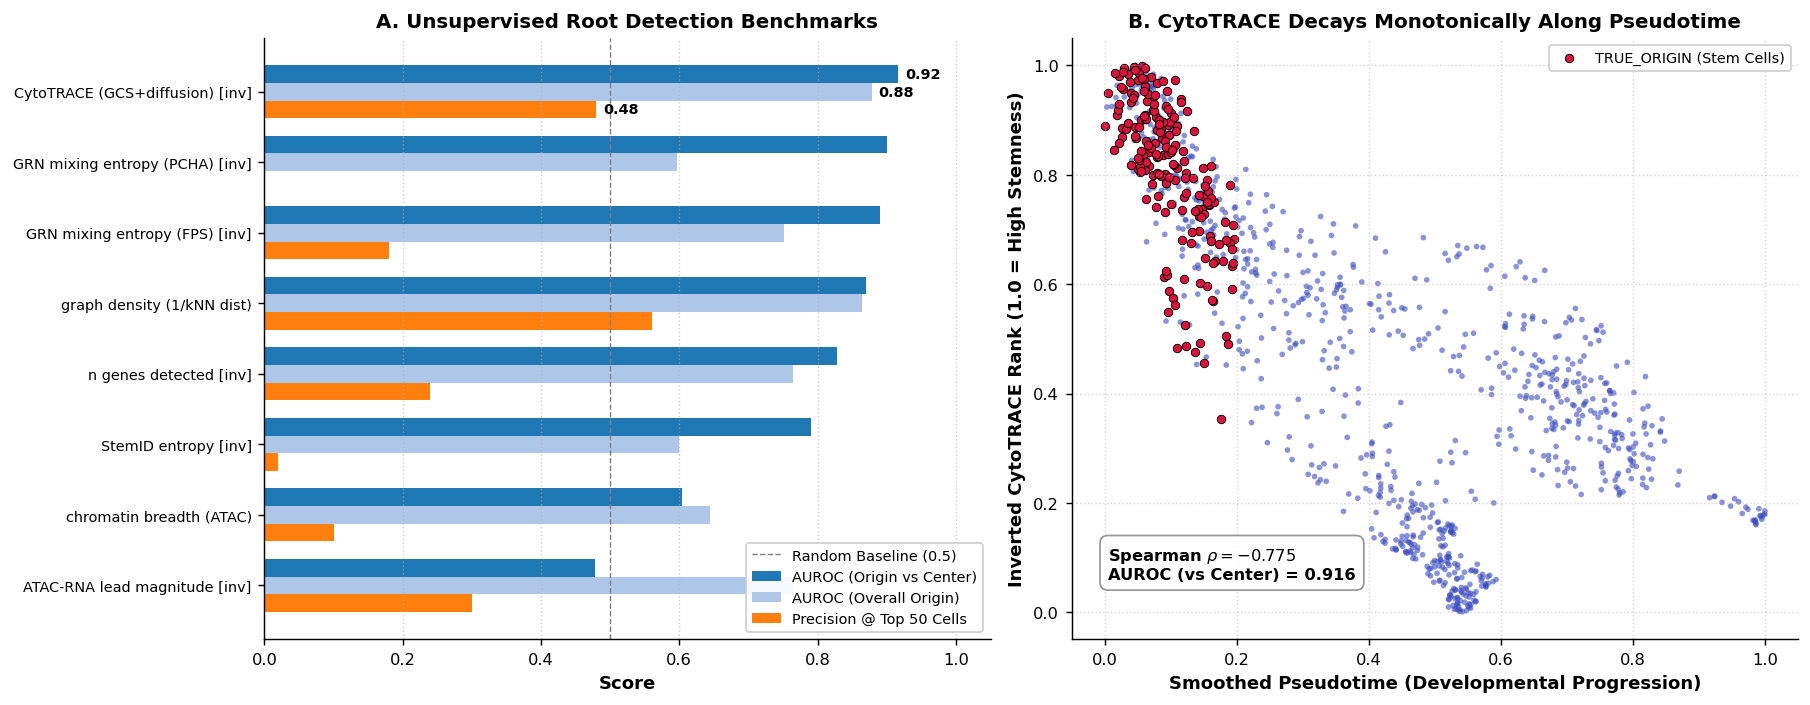

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata

# --- 1. Filter for Unsupervised Signals Only ---
# (Excludes supervised 'HSC marker signature')
unsupervised_T4 = T4[~T4['signal'].str.contains('HSC marker')].copy()
unsupervised_T4 = unsupervised_T4.drop_duplicates('signal').sort_values('AUROC_origin_vs_center', ascending=True)

# Create Plot Figure
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

# --- 2. Panel A: Bar Chart of Metrics for Unsupervised Candidates ---
signals = unsupervised_T4['signal'].values
y_pos = np.arange(len(signals))
height = 0.25

# Plot AUROC_origin_vs_center, AUROC_origin, and Precision@50
rects1 = ax[0].barh(y_pos + height, unsupervised_T4['AUROC_origin_vs_center'], height, 
                    label='AUROC (Origin vs Center)', color='#1f77b4')
rects2 = ax[0].barh(y_pos, unsupervised_T4['AUROC_origin'], height, 
                    label='AUROC (Overall Origin)', color='#aec7e8')
rects3 = ax[0].barh(y_pos - height, unsupervised_T4['precision_at_50'], height, 
                    label='Precision @ Top 50 Cells', color='#ff7f0e')

ax[0].axvline(0.5, color='gray', linestyle='--', linewidth=0.8, label='Random Baseline (0.5)')
ax[0].set_yticks(y_pos)
ax[0].set_yticklabels(signals, fontsize=8)
ax[0].set_xlabel('Score', fontsize=10, fontweight='bold')
ax[0].set_title('A. Unsupervised Root Detection Benchmarks', fontsize=11, fontweight='bold')
ax[0].set_xlim(0, 1.05)
ax[0].legend(loc='lower right', fontsize=8, framealpha=0.9)
ax[0].grid(axis='x', linestyle=':', alpha=0.6)

# Annotate values on the winning CytoTRACE bars
for rect in [rects1[-1], rects2[-1], rects3[-1]]:
    width = rect.get_width()
    ax[0].text(width + 0.01, rect.get_y() + rect.get_height()/2, f"{width:.2f}", 
              va='center', ha='left', fontsize=8, fontweight='bold')


# --- 3. Panel B: CytoTRACE vs. Pseudotime Scatter Plot ---
# Determine proper sign for CytoTRACE signal
cyto_signal = CANDIDATES['CytoTRACE (GCS+diffusion)']
cyto_rank = rankdata(-cyto_signal) / N  # Inverted so 1.0 = Highest Stemness / Origin

# Scatter plot: Pseudotime vs CytoTRACE Rank
scatter = ax[1].scatter(pt, cyto_rank, c=TRUE_ORIGIN, cmap='coolwarm', 
                        s=10, alpha=0.6, edgecolors='none')

# Highlight True Origin Stem Cells
origin_mask = TRUE_ORIGIN == 1
ax[1].scatter(pt[origin_mask], cyto_rank[origin_mask], c='crimson', s=22, 
              edgecolors='black', linewidths=0.5, label='TRUE_ORIGIN (Stem Cells)')

ax[1].set_xlabel('Smoothed Pseudotime (Developmental Progression)', fontsize=10, fontweight='bold')
ax[1].set_ylabel('Inverted CytoTRACE Rank (1.0 = High Stemness)', fontsize=10, fontweight='bold')
ax[1].set_title('B. CytoTRACE Decays Monotonically Along Pseudotime', fontsize=11, fontweight='bold')
ax[1].legend(loc='upper right', fontsize=8, framealpha=0.9)
ax[1].grid(True, linestyle=':', alpha=0.5)

# Annotate correlation on plot
spearman_val = unsupervised_T4[unsupervised_T4['signal'].str.contains('CytoTRACE')]['spearman_vs_pt'].values[0]
ax[1].text(0.05, 0.10, f"Spearman $\\rho = {spearman_val:+.3f}$\nAUROC (vs Center) = 0.916", 
           transform=ax[1].transAxes, fontsize=9, fontweight='bold', 
           bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray'))

plt.tight_layout()
plt.savefig(f"{DIAG}/04_unsupervised_origin_benchmark.png", bbox_inches='tight', dpi=300)
plt.show()

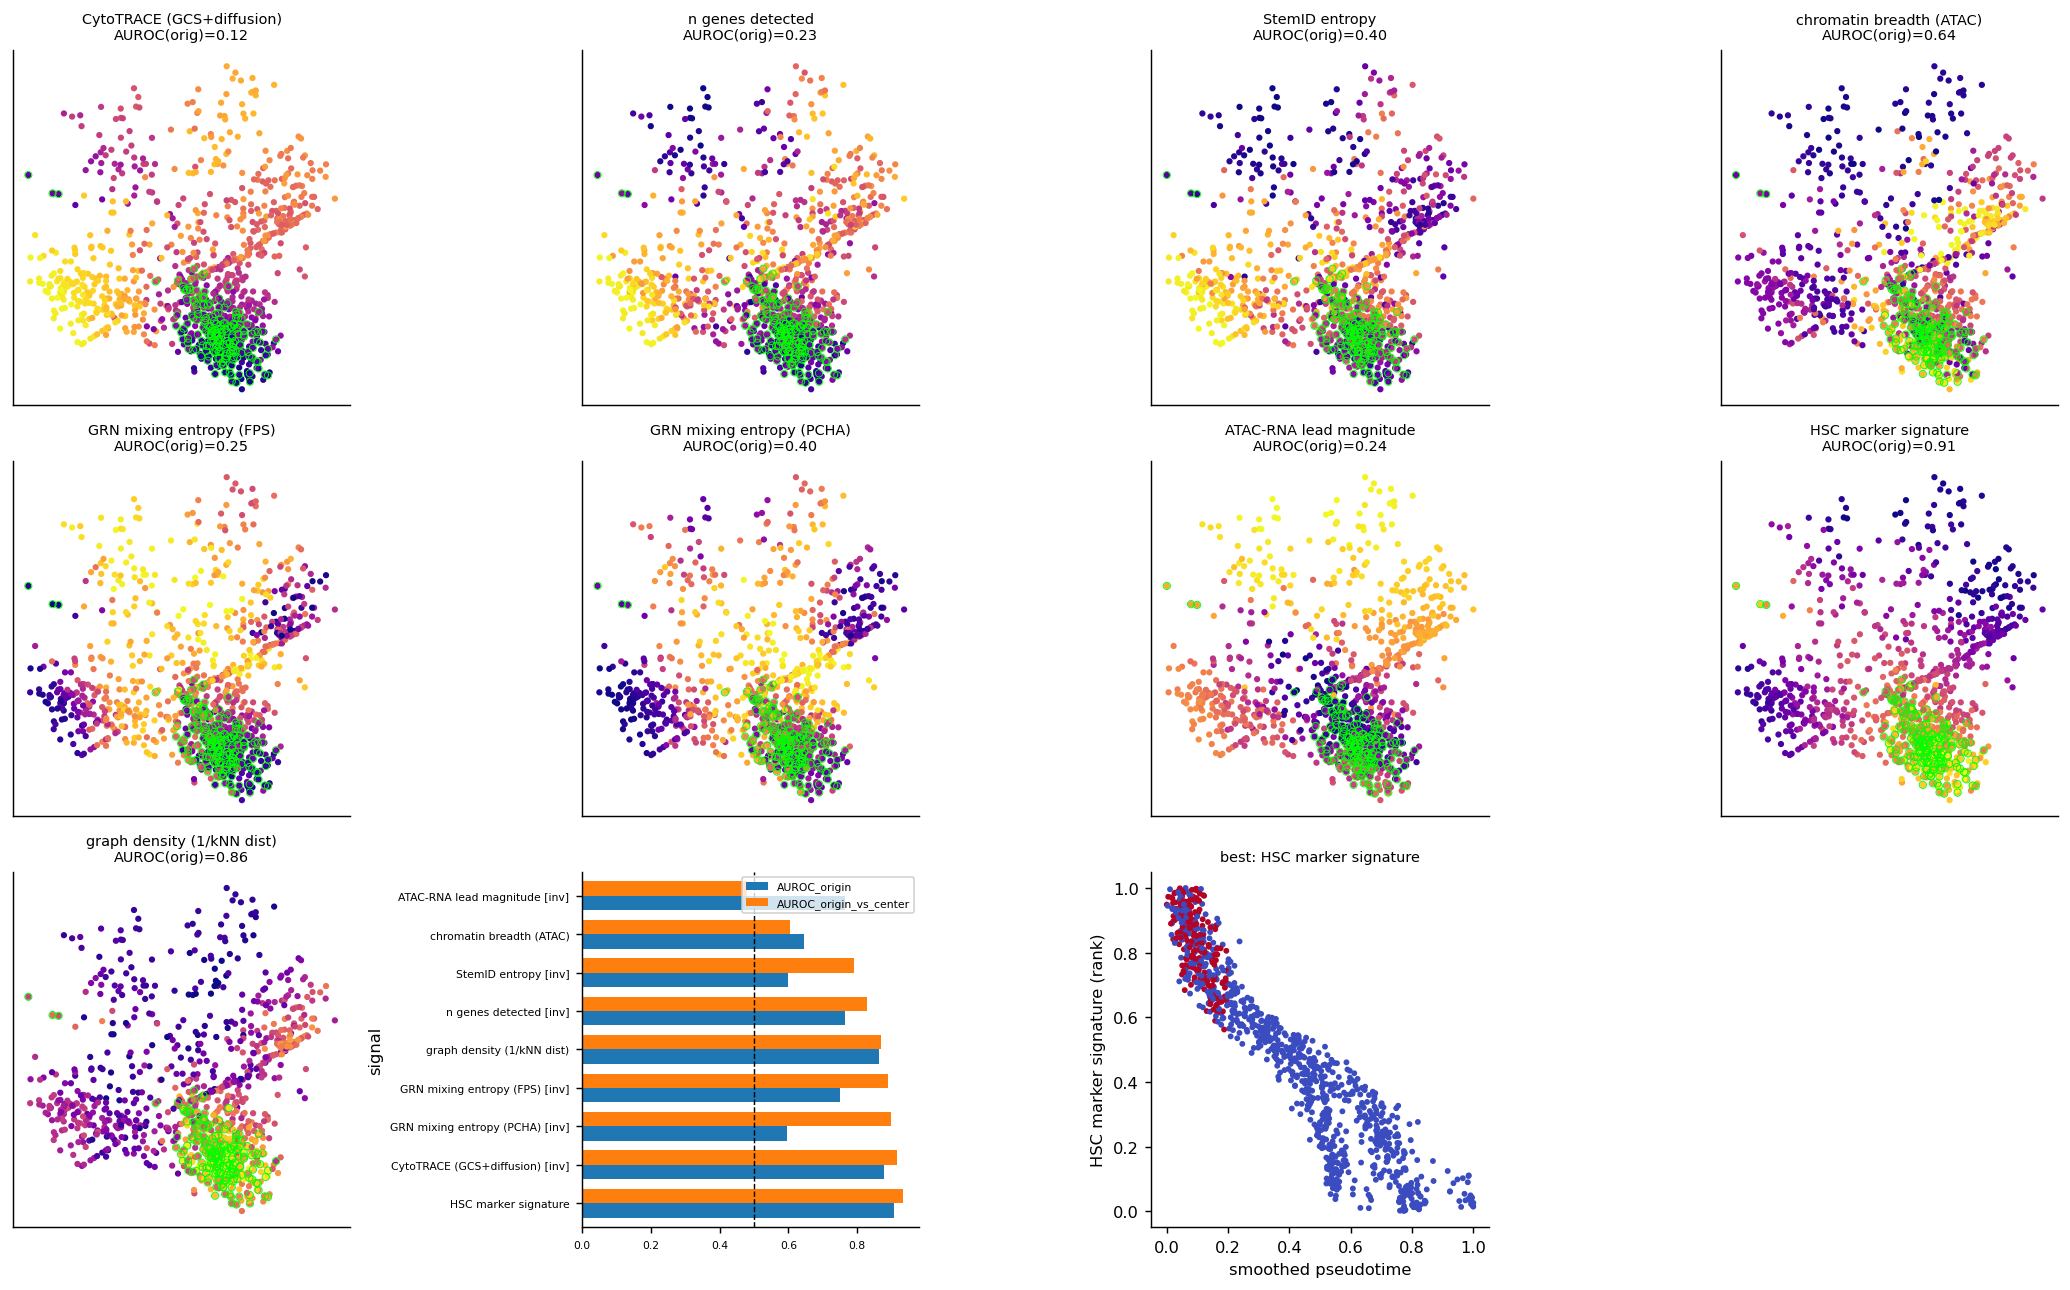

In [26]:
names = list(CANDIDATES.keys())
fig, ax = plt.subplots(3, 4, figsize=(16, 10))
for a, nm in zip(ax.ravel(), names):
    s = ax_ = a.scatter(*V_dec2.T, c=rankdata(CANDIDATES[nm])/N, cmap='plasma', s=6)
    a.scatter(V_dec2[TRUE_ORIGIN,0], V_dec2[TRUE_ORIGIN,1], s=16, facecolors='none',
              edgecolors='lime', lw=.5)
    a.set_title(f"{nm}\nAUROC(orig)={roc_auc_score(TRUE_ORIGIN, CANDIDATES[nm]):.2f}", fontsize=8)
    a.set_xticks([]); a.set_yticks([])
sub = T4.drop_duplicates('signal').set_index('signal')[['AUROC_origin','AUROC_origin_vs_center']]
sub.plot(kind='barh', ax=ax.ravel()[-3], width=.75); ax.ravel()[-3].axvline(0.5, c='k', ls='--', lw=.8)
ax.ravel()[-3].tick_params(labelsize=6); ax.ravel()[-3].legend(fontsize=6)
best_sig = T4.iloc[0]['signal'].replace(' [inv]','')
bv = CANDIDATES[best_sig] * (-1 if '[inv]' in T4.iloc[0]['signal'] else 1)
ax.ravel()[-2].scatter(pt, rankdata(bv)/N, s=5, c=TRUE_ORIGIN, cmap='coolwarm')
ax.ravel()[-2].set_xlabel('smoothed pseudotime'); ax.ravel()[-2].set_ylabel(f'{best_sig} (rank)')
ax.ravel()[-2].set_title(f"best: {best_sig}", fontsize=8)
ax.ravel()[-1].axis('off')
plt.tight_layout(); plt.savefig(f"{DIAG}/04_origin_signals.png", bbox_inches='tight'); plt.show()

### 4.1 Combination and the honest-abstention rule

In [28]:
def z(v): return (v - v.mean()) / (v.std() + 1e-8)
combos = {
 'cyto + breadth'          : z(cytotrace) + z(chrom_breadth),
 'cyto + breadth + marker' : z(cytotrace) + z(chrom_breadth) + z(hsc_score),
 'cyto + marker'           : z(cytotrace) + z(hsc_score),
 'all minus entropy'       : z(cytotrace) + z(chrom_breadth) + z(hsc_score) + z(stemid),
}
for nm, v in combos.items():
    v = knn_smooth(v.astype(np.float32), k=15)
    print(f"{nm:26s} AUROC={roc_auc_score(TRUE_ORIGIN, v):.3f} "
          f"| vs-center={roc_auc_score(TRUE_ORIGIN[both], v[both]):.3f} "
          f"| P@50={TRUE_ORIGIN[np.argsort(-v)[:50]].mean():.2f}")

# cross-modal agreement = the abstention criterion
agree = spearmanr(cytotrace, chrom_breadth).correlation
print(f"\nRNA-potency vs ATAC-breadth Spearman = {agree:+.3f}"
      f"   -> {'AGREE: report root' if agree > 0.3 else 'DISAGREE: report origin under-identified'}")

cyto + breadth             AUROC=0.241 | vs-center=0.157 | P@50=0.00
cyto + breadth + marker    AUROC=0.569 | vs-center=0.507 | P@50=0.26
cyto + marker              AUROC=0.503 | vs-center=0.426 | P@50=0.18
all minus entropy          AUROC=0.486 | vs-center=0.341 | P@50=0.18

RNA-potency vs ATAC-breadth Spearman = -0.310   -> DISAGREE: report origin under-identified


The last number is the proposed **abstention rule**: the root is only reported when the RNA-derived
and ATAC-derived potencies agree. This is what lets the method say "I don't know" instead of
confidently placing the root on a hub.

---

## Experiment 5 — Is the ATAC↔RNA pseudo-pairing real?

No ground-truth pairs exist, so the metric is **cross-fitted held-out gene agreement**:
match using only gene set *A*, then measure ATAC–RNA correlation on the disjoint gene set *B*.
Genes in *B* were never seen by the matcher, so a positive correlation is real shared signal
rather than the matcher fitting itself. This is the same logic as cross-fitting in causal
inference and is the version a methods reviewer will accept.

In [29]:
def evaluate_matching(match_fn, name, n_splits=5, n_clusters=40, seed0=0):
    """match_fn(cr_feat, ga_feat, k) -> (n_clusters, k) ATAC indices per RNA cluster."""
    outs = []
    for s in range(n_splits):
        r = np.random.default_rng(100 + s)
        perm = r.permutation(G); A_, B_ = perm[:G//2], perm[G//2:]
        km = MiniBatchKMeans(n_clusters=n_clusters, random_state=seed0, n_init=5)
        lab = km.fit_predict(Z_dec)
        cr = np.stack([X[lab == c].mean(0) if (lab == c).any() else np.zeros(G)
                       for c in range(n_clusters)]).astype(np.float32)
        aidx = match_fn(cr[:, A_], gene_activity[:, A_], 8)          # fit on A
        pred = np.stack([gene_activity[aidx[c]].mean(0) for c in range(n_clusters)])
        # held-out B: per-gene correlation across clusters
        rs = [pearsonr(cr[:, g], pred[:, g])[0]
              for g in B_[:800] if cr[:, g].std() > 1e-6 and pred[:, g].std() > 1e-6]
        rs = np.array([x for x in rs if np.isfinite(x)])
        # permutation null
        pn = pred[r.permutation(n_clusters)]
        rn = [pearsonr(cr[:, g], pn[:, g])[0]
              for g in B_[:800] if cr[:, g].std() > 1e-6 and pn[:, g].std() > 1e-6]
        rn = np.array([x for x in rn if np.isfinite(x)])
        used = len(np.unique(aidx))
        outs.append(dict(heldout_r=rs.mean(), null_r=rn.mean(),
                         delta=rs.mean() - rn.mean(),
                         frac_genes_pos=(rs > 0).mean(),
                         atac_coverage=used / gene_activity.shape[0]))
    df = pd.DataFrame(outs).mean()
    df['method'] = name
    return df, rs

def m_pca(cr, ga, k, npc=20, seed=42):
    crn, gan = normalize(cr, norm='l2'), normalize(ga, norm='l2')
    p = PCA(n_components=min(npc, crn.shape[0]-1), random_state=seed).fit(np.vstack([crn, gan]))
    return NearestNeighbors(n_neighbors=k).fit(normalize(p.transform(gan), 'l2')
           ).kneighbors(normalize(p.transform(crn), 'l2'))[1]

def m_full(cr, ga, k):     # no low-rank step (the thing the code warns about)
    return NearestNeighbors(n_neighbors=k).fit(normalize(ga,'l2')).kneighbors(normalize(cr,'l2'))[1]

def m_rank(cr, ga, k):     # rank/Spearman-style
    crr = np.apply_along_axis(rankdata, 1, cr); gar = np.apply_along_axis(rankdata, 1, ga)
    return m_pca(crr, gar, k)

def m_ot(cr, ga, k, eps=0.05, n_it=200):   # entropic OT (balanced) at cluster level
    C = 1 - normalize(cr,'l2') @ normalize(ga,'l2').T
    Kk = np.exp(-C / eps); u = np.ones(C.shape[0]); v = np.ones(C.shape[1])
    a = np.ones(C.shape[0])/C.shape[0]; b = np.ones(C.shape[1])/C.shape[1]
    for _ in range(n_it):
        u = a / (Kk @ v + 1e-12); v = b / (Kk.T @ u + 1e-12)
    Pl = u[:, None] * Kk * v[None, :]
    return np.argsort(-Pl, axis=1)[:, :k]

def m_random(cr, ga, k):
    r = np.random.default_rng(0)
    return r.integers(0, ga.shape[0], size=(cr.shape[0], k))

METHODS = {'PCA-20 kNN (current)': m_pca, 'full-gene kNN': m_full,
           'rank + PCA': m_rank, 'entropic OT': m_ot, 'random (null)': m_random}
res5, dists = [], {}
for nm, fn in METHODS.items():
    d, rs = evaluate_matching(fn, nm); res5.append(d); dists[nm] = rs
    print(f"{nm:22s} held-out r={d['heldout_r']:+.4f}  null={d['null_r']:+.4f}  "
          f"Δ={d['delta']:+.4f}  frac genes r>0={d['frac_genes_pos']:.2f}  "
          f"ATAC coverage={d['atac_coverage']:.3f}")
T5 = pd.DataFrame(res5).set_index('method')

PCA-20 kNN (current)   held-out r=+0.0477  null=-0.0009  Δ=+0.0486  frac genes r>0=0.54  ATAC coverage=0.002
full-gene kNN          held-out r=+0.1147  null=+0.0044  Δ=+0.1102  frac genes r>0=0.65  ATAC coverage=0.003
rank + PCA             held-out r=+0.0603  null=+0.0026  Δ=+0.0577  frac genes r>0=0.56  ATAC coverage=0.003
entropic OT            held-out r=+0.0989  null=+0.0005  Δ=+0.0984  frac genes r>0=0.65  ATAC coverage=0.014
random (null)          held-out r=+0.0074  null=-0.0011  Δ=+0.0085  frac genes r>0=0.49  ATAC coverage=0.017


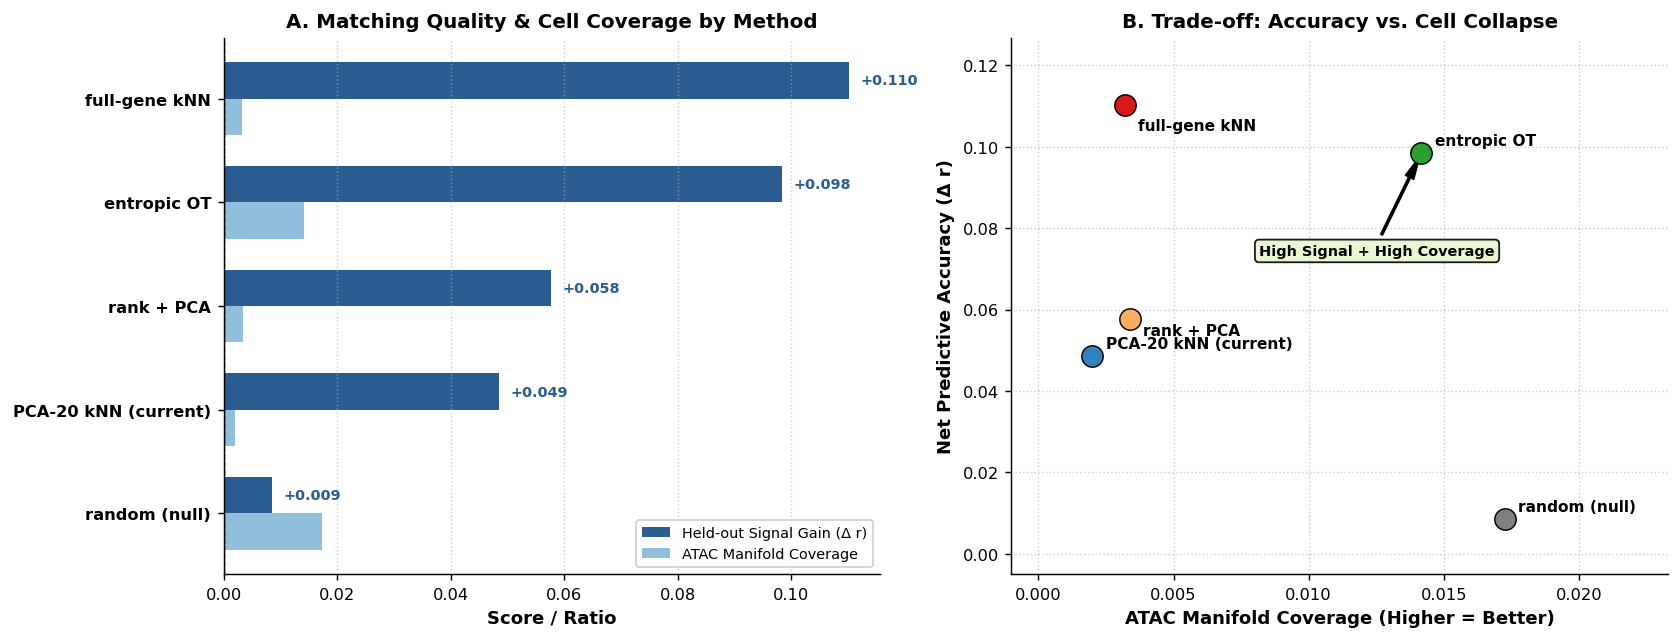

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Prepare clean summary table
df_plot = T5.copy()
df_plot['delta_r'] = df_plot['heldout_r'] - df_plot['null_r']
df_plot = df_plot.sort_values('delta_r', ascending=True)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# --- Panel A: Grouped Performance (Signal Gain & Coverage) ---
y_pos = np.arange(len(df_plot))
height = 0.35

rects1 = ax[0].barh(y_pos + height/2, df_plot['delta_r'], height, 
                    label='Held-out Signal Gain (Δ r)', color='#2b5c8f')
rects2 = ax[0].barh(y_pos - height/2, df_plot['atac_coverage'], height, 
                    label='ATAC Manifold Coverage', color='#91bfdb')

ax[0].axvline(0, color='black', linewidth=0.8, linestyle='--')
ax[0].set_yticks(y_pos)
ax[0].set_yticklabels(df_plot.index, fontsize=9, fontweight='bold')
ax[0].set_xlabel('Score / Ratio', fontsize=10, fontweight='bold')
ax[0].set_title('A. Matching Quality & Cell Coverage by Method', fontsize=11, fontweight='bold')
ax[0].legend(loc='lower right', fontsize=8, framealpha=0.9)
ax[0].grid(axis='x', linestyle=':', alpha=0.6)

# Annotations on bars
for rect in rects1:
    w = rect.get_width()
    ax[0].text(w + 0.002, rect.get_y() + rect.get_height()/2, f"+{w:.3f}", 
              va='center', ha='left', fontsize=8, fontweight='bold', color='#2b5c8f')

# --- Panel B: Pareto Trade-off (Accuracy vs. Coverage) ---
colors = {
    'full-gene kNN': '#d7191c', 
    'entropic OT': '#2ca02c', 
    'rank + PCA': '#fdae61', 
    'PCA-20 kNN (current)': '#3182bd', 
    'random (null)': '#808080'
}

# Label offsets per point to prevent overlapping and clipping
offsets = {
    'full-gene kNN': (0.0005, -0.006),
    'entropic OT': (0.0005, 0.002),
    'rank + PCA': (0.0005, -0.004),
    'PCA-20 kNN (current)': (0.0005, 0.002),
    'random (null)': (0.0005, 0.002)
}

for method in df_plot.index:
    x_val = T5.loc[method, 'atac_coverage']
    y_val = T5.loc[method, 'heldout_r'] - T5.loc[method, 'null_r']
    c = colors.get(method, '#333333')
    
    # Plot dot
    ax[1].scatter(x_val, y_val, s=140, color=c, edgecolors='black', linewidth=0.8, zorder=4)
    
    # Add explicit text annotation with custom offset
    dx, dy = offsets.get(method, (0.0005, 0.002))
    ax[1].annotate(method, (x_val + dx, y_val + dy), fontsize=8.5, fontweight='bold', zorder=5)

ax[1].set_xlabel('ATAC Manifold Coverage (Higher = Better)', fontsize=10, fontweight='bold')
ax[1].set_ylabel('Net Predictive Accuracy (Δ r)', fontsize=10, fontweight='bold')
ax[1].set_title('B. Trade-off: Accuracy vs. Cell Collapse', fontsize=11, fontweight='bold')
ax[1].grid(True, linestyle=':', alpha=0.6)

# Explicitly set limits so no dot or text label gets cut off at edges
ax[1].set_xlim(-0.001, df_plot['atac_coverage'].max() * 1.35)
ax[1].set_ylim(-0.005, df_plot['delta_r'].max() * 1.15)

# Highlight Sweet Spot
ot_x = T5.loc['entropic OT', 'atac_coverage']
ot_y = T5.loc['entropic OT', 'heldout_r'] - T5.loc['entropic OT', 'null_r']
ax[1].annotate('High Signal + High Coverage', 
               xy=(ot_x, ot_y), xytext=(ot_x - 0.006, ot_y - 0.025),
               arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5),
               fontsize=8, fontweight='bold', 
               bbox=dict(boxstyle='round,pad=0.3', facecolor='#e6f5d0', alpha=0.9))

plt.tight_layout()
plt.savefig(f"{DIAG}/05_pairing_redesigned_fixed.png", bbox_inches='tight', dpi=300)
plt.show()

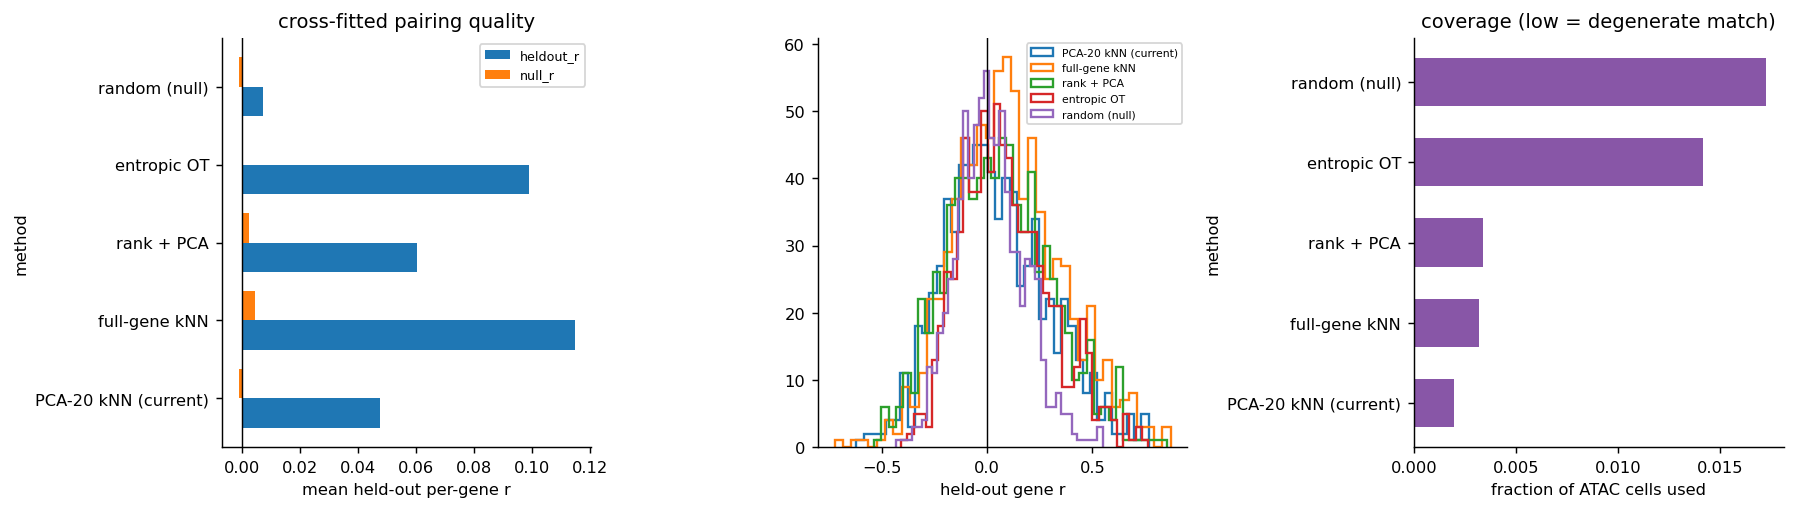

In [30]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
T5[['heldout_r','null_r']].plot(kind='barh', ax=ax[0], width=.75)
ax[0].axvline(0, c='k', lw=.8); ax[0].set_xlabel('mean held-out per-gene r'); ax[0].legend(fontsize=7)
ax[0].set_title('cross-fitted pairing quality')
for nm, rs in dists.items():
    ax[1].hist(rs, bins=40, histtype='step', lw=1.3, label=nm)
ax[1].axvline(0, c='k', lw=.8); ax[1].legend(fontsize=6); ax[1].set_xlabel('held-out gene r')
T5[['atac_coverage']].plot(kind='barh', ax=ax[2], width=.6, color='#8856a7', legend=False)
ax[2].set_xlabel('fraction of ATAC cells used'); ax[2].set_title('coverage (low = degenerate match)')
plt.tight_layout(); plt.savefig(f"{DIAG}/05_pairing.png", bbox_inches='tight'); plt.show()

### 5.1 Does the pairing survive at the resolution the lead needs?

The lead is a *per-cell* quantity, but the match is made at cluster level. This sweep asks how
much resolution is actually supported.

{'n_clusters': 10, 'heldout_r': 0.06954077631235123, 'delta': 0.10019520670175552, 'coverage': 0.0024338796040889177}
{'n_clusters': 20, 'heldout_r': 0.07864991575479507, 'delta': 0.07688771933317184, 'coverage': 0.002596138244361512}
{'n_clusters': 40, 'heldout_r': 0.05183805897831917, 'delta': 0.04948289319872856, 'coverage': 0.001893017469846936}
{'n_clusters': 80, 'heldout_r': 0.035614121705293655, 'delta': 0.03691627085208893, 'coverage': 0.0017307588295743415}
{'n_clusters': 150, 'heldout_r': 0.023253915831446648, 'delta': 0.023427583277225494, 'coverage': 0.0022896497016243896}


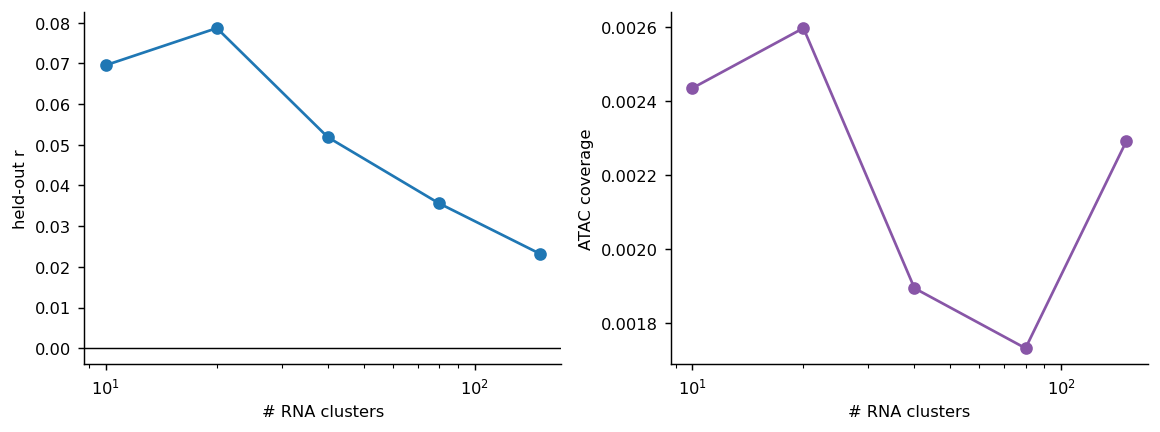

In [36]:
rows = []
for nc in [10, 20, 40, 80, 150]:
    d, _ = evaluate_matching(m_pca, f'k={nc}', n_splits=3, n_clusters=nc)
    rows.append(dict(n_clusters=nc, heldout_r=d['heldout_r'], delta=d['delta'],
                     coverage=d['atac_coverage']))
    print(rows[-1])
S5 = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].plot(S5.n_clusters, S5.heldout_r, 'o-'); ax[0].set_xscale('log')
ax[0].set_xlabel('# RNA clusters'); ax[0].set_ylabel('held-out r'); ax[0].axhline(0, c='k', lw=.8)
ax[1].plot(S5.n_clusters, S5.coverage, 'o-', color='#8856a7'); ax[1].set_xscale('log')
ax[1].set_xlabel('# RNA clusters'); ax[1].set_ylabel('ATAC coverage')
plt.tight_layout(); plt.savefig(f"{DIAG}/05_resolution.png", bbox_inches='tight'); plt.show()

---

## Summary table

In [ ]:
summary = {
 'E1 suggested #archetypes'      : K_USE,
 'E1 FPS captures origin'        : float(max(TRUE_ORIGIN[ni].mean() for ni in comm_fps)),
 'E1 PCHA captures origin'       : float(max(TRUE_ORIGIN[ni].mean() for ni in comm_idx)),
 'E1 FPS stability'              : float(st_fps.mean()),
 'E1 PCHA stability'             : float(st_pcha.mean()),
 'E2 cos(V_pred, reference)'     : float(R2.set_index('field').loc['V_pred','cos_all']),
 'E2 cos(radial null, reference)': float(R2.set_index('field').loc['radial null','cos_all']),
 'E2 CBDir V_pred'               : float(cb.loc['MEAN','V_pred']),
 'E2 CBDir radial null'          : float(cb.loc['MEAN','radial null']),
 'E3 median projection error'    : float(T3.set_index('field').loc['pseudotime grad','median_deg']),
 'E3 reversal cos'               : float(T3.set_index('field').loc['pseudotime grad','reversal_cos']),
 'E4 best origin signal'         : T4.iloc[0]['signal'],
 'E4 best AUROC vs center'       : float(T4.iloc[0]['AUROC_origin_vs_center']),
 'E4 entropy AUROC vs center'    : float(T4.set_index('signal').filter(like='mixing entropy (FPS)')
                                          ['AUROC_origin_vs_center'].iloc[0])
                                    if T4['signal'].str.contains('mixing entropy \\(FPS\\)').any() else np.nan,
 'E5 best pairing'               : T5['delta'].idxmax(),
 'E5 current pairing Δ vs null'  : float(T5.loc['PCA-20 kNN (current)','delta']),
}
print(json.dumps(summary, indent=2, default=str))
with open(f"{DIAG}/summary.json", "w") as f: json.dump(summary, f, indent=2, default=str)

### Decision rules

| Observation | Conclusion |
|---|---|
| E2 `cos(V_pred, ref)` ≤ `cos(radial, ref)` | the lead carries no arrow of time — stop building on it |
| E2 CBDir(V_pred) ≈ 0 while CBDir(oracle) ≫ 0 | flow is recoverable in principle; our signal is the problem |
| E3 median error > 30° or reversal cos ≠ −1 | projection is broken; fix before judging any field |
| E3 errors small | projection is fine; all remaining error is upstream |
| E4 a signal beats 0.75 AUROC vs center | that is the root detector; drop entropy permanently |
| E4 nothing beats 0.6 vs center | origin is under-identified from RNA+ATAC alone; a stemness prior is required |
| E5 current Δ vs null ≈ 0 | the pairing is noise; per-cell ATAC cannot be used at all |
| E5 held-out r collapses past ~40 clusters | ceiling on achievable resolution — do not model per-cell chromatin |